# Customer Segmentation & Product Recommendation Analysis
### Data Consultant Report | Online Retail Transaction Dataset

**Project objective**

Translate one year of retail transaction data into actionable customer segments, purchasing-pattern insights, and product recommendations.

**Business questions**
1. Who are the company's customers, based on their purchasing behaviour?
2. Which products are commonly purchased together?
3. Which products could be recommended to existing and new customers?
4. What practical actions could management take from these findings?

## Executive Summary

This project analyzes the Online Retail transaction dataset to support customer understanding, cross-selling, and product discovery. The workflow combines transaction-level data quality assessment, customer-level RFM feature engineering, K-Means clustering, PCA visualization, Market Basket Analysis, and a hybrid product recommendation approach.

**Headline findings**

- The source dataset contains **541,909 transaction lines**, **4,372 identified customers**, and **4,070 product codes**. Customer IDs are missing from approximately one quarter of the transaction lines, so customer-level analysis necessarily uses a smaller, identifiable subset.
- RFM analysis produced **4,338 customers** for segmentation. Four K-Means segments were selected as a business-interpretability trade-off, although a two-cluster solution achieved a higher silhouette score.
- The four segments differ in purchase recency, invoice frequency, and total recorded spend. The largest group contains 1,642 customers; the high-value, frequent-purchasing group contains 685 customers.
- Market Basket Analysis identified **1,902 frequent itemsets** and **1,824 association rules** using a 1% minimum support threshold and 30% minimum confidence threshold. Regency teacup designs, jumbo bags, lunch bags, and gardeners' kneeling pads showed useful cross-selling patterns.
- In the time-based recommendation evaluation, the hybrid approach achieved **7.53% Precision@5** and **1.13% Recall@5**, compared with **7.03%** and **1.02%** for the association-rule-only baseline. The hybrid approach also supplied five recommendations to all **1,893 evaluated customers**.

**Management takeaway**

Use the RFM segments to tailor retention, reactivation, and repeat-purchase campaigns. Test complementary-product placements and the hybrid recommendations in a controlled pilot before broad deployment. Recommendation metrics are modest, so the system should be treated as a decision-support prototype rather than a proven revenue driver.

## Analytical Approach and Reporting Convention

This notebook is structured as a professional analytical report:

- **Markdown cells** explain the business question, analytical reasoning, assumptions, decisions, findings, and limitations.
- **Code cells** perform the data preparation, analysis, modelling, and validation.
- Each major decision is linked to its business or technical purpose. Exploratory outputs are distinguished from final model results.

**Reproducibility note:** The notebook expects the Excel file at `data/online_retail.xlsx`, relative to the notebook's working directory. Run the notebook from the project root (or adjust the path to match the project structure). Run all cells from top to bottom before submission so that outputs correspond to the saved code.


# Part 1 — Business Understanding & Data Exploration

## 1.1 Business Understanding

### Business Problem

The retailer has a large volume of historical transactions but limited visibility into customer purchasing behaviour. Management needs evidence to understand who its customers are, which products are purchased together, and where targeted marketing or cross-selling may be useful.

### Analytical Objective

The project uses unsupervised learning and transaction-pattern analysis to:
- Identify customer groups with similar purchasing behaviour.
- Discover products that frequently appear in the same invoice.
- Generate product recommendations for existing customers and a popularity-based fallback for customers without purchase history.
- Translate the analytical findings into practical business actions.

### Why These Methods Are Appropriate

The dataset contains transaction records but no predefined customer-segment labels or recommendation outcomes. Therefore, supervised classification is not the natural starting point. RFM feature engineering and clustering can reveal customer groups without requiring pre-existing labels. Association rules can identify co-purchase patterns at invoice level, while a simple hybrid recommender can combine customer purchase history with popular products.

**Scope and interpretation:** The analysis describes historical behaviour in the supplied dataset. It does not establish why customers behave in a particular way, prove causation, or guarantee that a recommended product will be purchased.


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.preprocessing import StandardScaler

# Machine learning – clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

# Model evaluation
from sklearn.metrics import silhouette_score

# Dimensionality reduction
from sklearn.decomposition import PCA

# Market Basket Analysis
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

In [2]:
# Load dataset
df = pd.read_excel("data/online_retail.xlsx")

# Display the first few rows of the dataset
print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [3]:
# Check the number of rows and columns in the dataset
df.shape

(541909, 8)

In [4]:
# Display column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
# Check missing values in each column
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

### Checking Missing Values

After checking the dataset, I found that some values are missing in two columns:

- **Description:** 1,454 missing values.
- **CustomerID:** 135,080 missing values.

Most of the missing values are in the CustomerID column, which is almost 25% of the dataset.

I think this could affect our customer segmentation because we need CustomerID to identify customers and group their purchases.

For now, I will keep the original data as it is. I will decide how to handle these missing values later when I start the data-cleaning part.

In [6]:
# Check the number of duplicate rows
df.duplicated().sum()

np.int64(5268)

### Checking Duplicate Records

I also checked the dataset for duplicate rows and found 5,268 duplicates.

This means that some records appear more than once with exactly the same information.

These duplicate records could affect the analysis if they are counted more than once. I will investigate and handle them during the data-cleaning stage.

For now, I am keeping the original dataset unchanged.

In [7]:
# Count the number of unique customers
df['CustomerID'].nunique()

4372

### Checking Unique Customers

I checked the CustomerID column to find out how many different customers are included in the dataset.

The result shows **4,372 unique customers**.

Although the dataset has more than 541,000 rows, the same customer can appear many times because they may have made several purchases.

This information will be useful later when I group the data by customer for the segmentation analysis.

In [8]:
# Count the number of unique products
df['StockCode'].nunique()

4070

### Checking Unique Products

I checked the StockCode column to find out how many different products are included in the dataset.

The result shows **4,070 unique product codes**.

This means the dataset contains a large variety of products, and some products appear in multiple transactions.

This information will be useful later when I explore the top-selling products and perform Market Basket Analysis.

In [9]:
# Get statistical information about numerical columns
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


### Exploring the Numerical Data

I used `df.describe()` to get a summary of the numerical columns in the dataset.

Some observations I noticed:

- The average quantity is around 9.55, but I also found negative and very large quantity values.
- The average unit price is around 4.61. I noticed that some prices are negative, so I will need to investigate them later.
- The CustomerID column contains customer identification numbers, so its average is not very useful for understanding customer behaviour.
- The transaction dates range from December 2010 to December 2011.

I noticed some unusual values in the Quantity and UnitPrice columns. I will investigate these during the data-cleaning stage instead of changing anything now.

In [10]:
# Count the number of unique invoices
df['InvoiceNo'].nunique()


25900

### Checking Unique Invoices

I checked the InvoiceNo column to find out how many different invoices are included in the dataset.

The result shows **25,900 unique invoices**.

This means that the dataset contains many transactions, and one invoice can include more than one product.

This information will be useful later when I analyze which products are frequently purchased together.

In [11]:
first_date = df['InvoiceDate'].min()
last_date = df['InvoiceDate'].max()

print(first_date)
print(last_date)

2010-12-01 08:26:00
2011-12-09 12:50:00


### Checking Transaction Dates

I checked the InvoiceDate column to find the earliest and latest transaction dates in the dataset.

The results show that:

- The first transaction was on **1 December 2010**.
- The last transaction was on **9 December 2011**.

This means the dataset contains transactions covering approximately one year.

This information will help me understand the period covered by the customers' purchasing history and will be useful later when analyzing their buying behaviour.

In [12]:
# Count records with negative quantities
negative_quantity_count = df[df['Quantity'] < 0].shape[0]
print(negative_quantity_count)

10624


### Checking Negative Quantities

I checked the Quantity column to see if there are any negative values.

The result shows **10,624 records** with negative quantities.

I think these records could be related to returned or cancelled purchases because the quantity is below zero.

I will investigate these records further during the data-cleaning stage before deciding what to do with them.

In [13]:
# Count records with negative unit prices
negative_unit_price_count = df[df['UnitPrice'] < 0].shape[0]
print(negative_unit_price_count)

2


### Checking Negative Unit Prices

I checked the UnitPrice column and found only **2 records** with negative prices.

Although this is a very small number compared with the full dataset, I need to investigate these records because product prices are normally expected to be positive.

I will check these records during the data-cleaning stage before deciding how to handle them.

In [14]:
# Count cancelled invoices 
canceled_invoices_count = df[df['InvoiceNo'].str.startswith('C', na=False)].shape[0]
print(canceled_invoices_count)

9288


### Checking Cancelled Invoices

I checked the InvoiceNo column to find transactions with invoice numbers starting with the letter C.

I found **9,288 records** that match this condition.

These records appear to be related to cancelled transactions. I also noticed that the number is different from the negative quantity records I checked earlier.

I will investigate these records further during data cleaning before deciding how to handle them.

In [15]:
# Calculate the purchase value
df['PurchaseValue'] = df['Quantity'] * df['UnitPrice']

# Display the first five purchase values
df[['Quantity', 'UnitPrice', 'PurchaseValue']].head()

,Quantity,UnitPrice,PurchaseValue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


### Calculating Purchase Value

I created a new column called `PurchaseValue` to calculate the value of each product line.

I calculated it by multiplying the Quantity by the UnitPrice.

For example, in the first row, 6 items multiplied by 2.55 gives a purchase value of 15.30.

I will use this column later to understand customer spending and explore the distribution of purchase values.

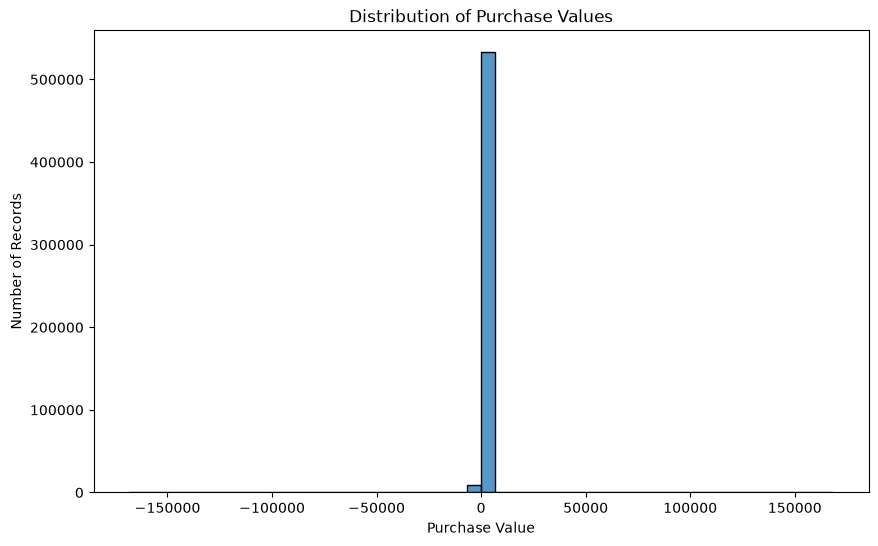

In [16]:
# Visualize the distribution of purchase values

plt.figure(figsize=(10, 6))

sns.histplot(df['PurchaseValue'], bins=50)

plt.title('Distribution of Purchase Values')
plt.xlabel('Purchase Value')
plt.ylabel('Number of Records')

plt.show()

### Distribution of Purchase Values

I created a histogram to understand how the purchase values are distributed in the dataset.

From the chart, I noticed that most purchase values are concentrated around the lower values. I also noticed some very large positive and negative values.

These unusual values make the chart look compressed and difficult to read.

I think some of the negative values could be related to returned or cancelled purchases. I will investigate these records further during the data-cleaning stage.

In [17]:
# Check the statistical summary of PurchaseValue
df['PurchaseValue'].describe()

count    541909.000000
mean         17.987795
std         378.810824
min     -168469.600000
25%           3.400000
50%           9.750000
75%          17.400000
max      168469.600000
Name: PurchaseValue, dtype: float64

In [18]:
# Check the 1st and 99th percentiles
df['PurchaseValue'].quantile([0.01, 0.99])

0.01     -6.58
0.99    180.00
Name: PurchaseValue, dtype: float64

### Further Investigation of Purchase Values

After checking the statistical summary, I noticed that the purchase values have a very wide range.

The minimum value is -168,469.60, while the maximum is 168,469.60. However, the median is only 9.75.

I also checked the 1st and 99th percentiles and found that the values range from approximately -6.58 to 180.00.

This shows that there are some extremely large values compared with most of the other records. These values are affecting how the histogram looks.

I will keep these records for now and investigate them further during data cleaning.

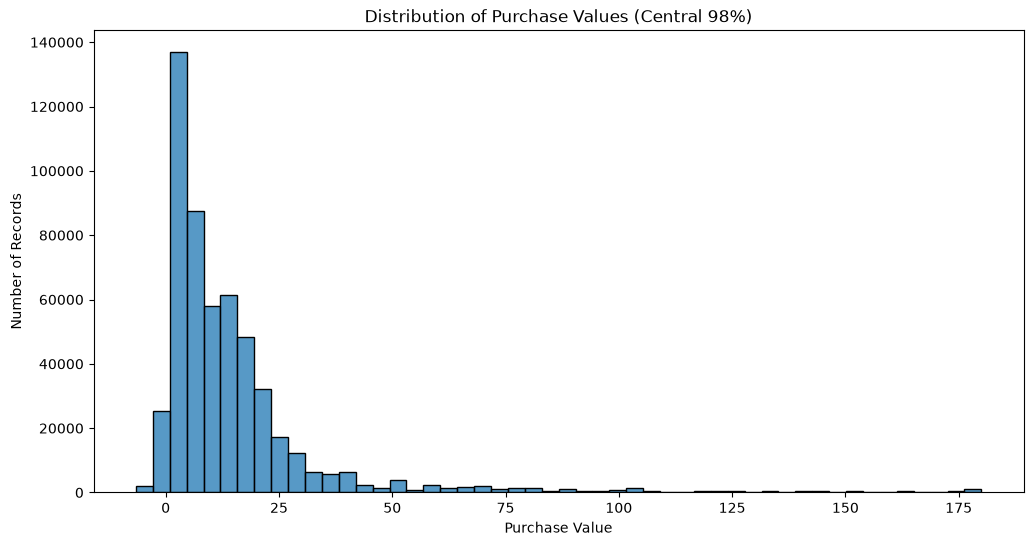

In [19]:
# Select purchase values between the 1st and 99th percentiles

lower_limit = df['PurchaseValue'].quantile(0.01)
upper_limit = df['PurchaseValue'].quantile(0.99)

purchase_values_filtered = df[
    (df['PurchaseValue'] >= lower_limit) &
    (df['PurchaseValue'] <= upper_limit)
]['PurchaseValue']

# Create the histogram using the filtered values

plt.figure(figsize=(12, 6))

sns.histplot(purchase_values_filtered, bins=50)

plt.title('Distribution of Purchase Values (Central 98%)')
plt.xlabel('Purchase Value')
plt.ylabel('Number of Records')

plt.show()

### Looking at the Distribution More Closely

I created another histogram using the values between the 1st and 99th percentiles to get a clearer view of the purchase values.

The second chart makes it easier to see where most of the purchase values are concentrated.

I noticed that most values are between approximately 0 and 20. As the purchase value increases, the number of records becomes smaller. There are also some negative values in the distribution.

This helped me understand the data better and showed that most product-line purchases have relatively low values.

I kept both charts because the first shows the complete distribution, while the second focuses on the central 98% of the values.


In [20]:
# Calculate the total quantity sold for each product

top_products = df.groupby('Description')['Quantity'].sum()

# Sort products from highest to lowest quantity
top_products = top_products.sort_values(ascending=False)

# Display the 10 best-selling products
top_products.head(10)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53847
JUMBO BAG RED RETROSPOT               47363
ASSORTED COLOUR BIRD ORNAMENT         36381
POPCORN HOLDER                        36334
PACK OF 72 RETROSPOT CAKE CASES       36039
WHITE HANGING HEART T-LIGHT HOLDER    35317
RABBIT NIGHT LIGHT                    30680
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26315
PACK OF 60 PINK PAISLEY CAKE CASES    24753
Name: Quantity, dtype: int64

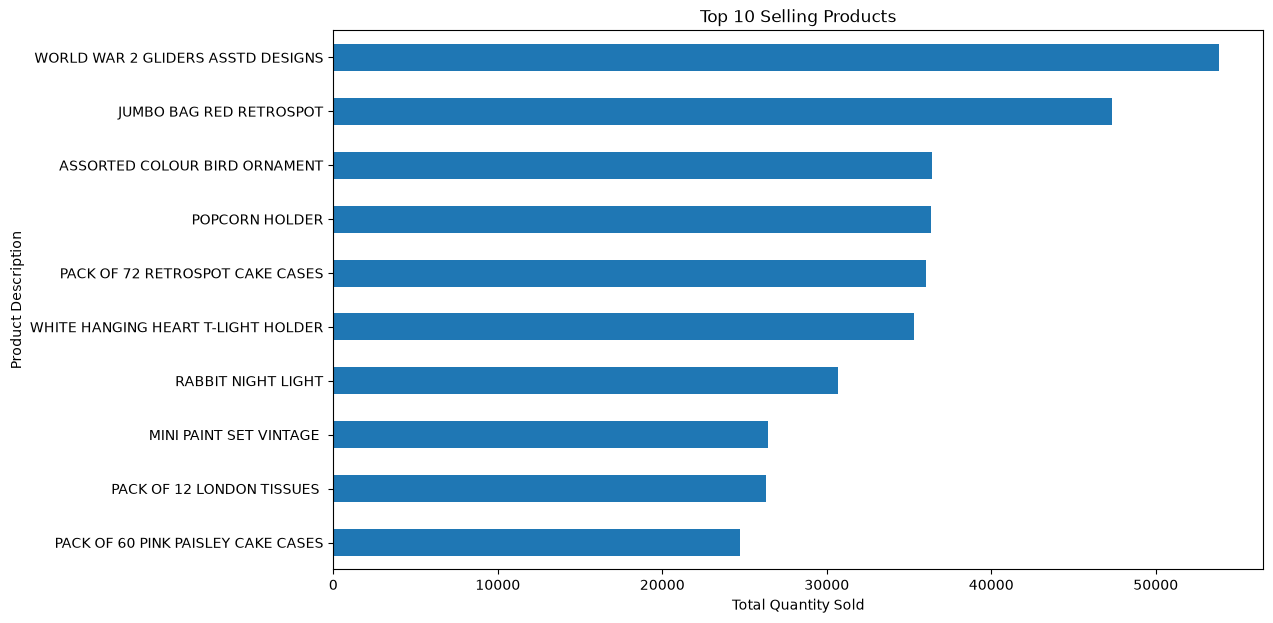

In [21]:
# Create a bar chart of the top 10 selling products

plt.figure(figsize=(12, 7))

top_products.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Selling Products')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product Description')

plt.show()

### Top-Selling Products

I created a bar chart to identify the 10 products with the highest total quantities in the dataset.

From the chart, I noticed that WORLD WAR 2 GLIDERS ASSTD DESIGNS has the highest recorded quantity, with 53,847 units. JUMBO BAG RED RETROSPOT comes second, with 47,363 units.

I also noticed that several products have similar quantities, especially those ranked between third and sixth place.

This gives me an initial idea of which products have higher sales volumes. However, these results are based on the original dataset, so I will review them again after cleaning the data and handling cancelled transactions and negative quantities.

In [22]:
# Count unique customers in each country

customers_by_country = df.groupby('Country')['CustomerID'].nunique()

# Sort countries by number of customers
customers_by_country = customers_by_country.sort_values(ascending=False)

# Display the top 10 countries
customers_by_country.head(10)

Country
United Kingdom    3950
Germany             95
France              87
Spain               31
Belgium             25
Switzerland         21
Portugal            19
Italy               15
Finland             12
Austria             11
Name: CustomerID, dtype: int64

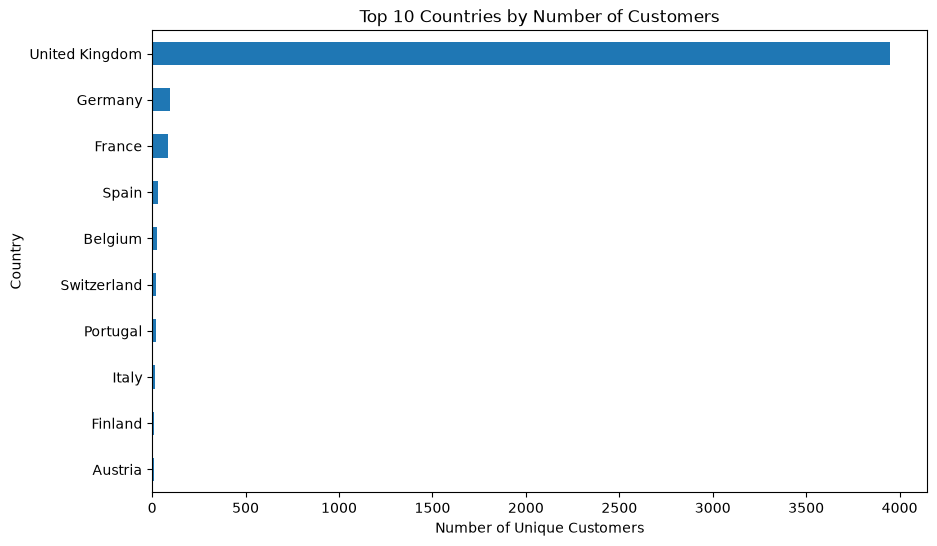

In [23]:
# Select the top 10 countries
top_10_countries = customers_by_country.head(10)

# Create a horizontal bar chart
top_10_countries.sort_values().plot(kind='barh', figsize=(10, 6))

# Add chart title and labels
plt.title('Top 10 Countries by Number of Customers')
plt.xlabel('Number of Unique Customers')
plt.ylabel('Country')

plt.show()

### Customer Distribution by Country

I created a bar chart to explore how customers are distributed across different countries.

From the chart, I noticed that the United Kingdom has the highest number of unique customers, with 3,950 customers. Germany and France come next, with 95 and 87 customers respectively.

The chart shows that most of the company's customers are based in the United Kingdom, while the other countries have much smaller customer numbers.

This gives us an initial understanding of the company's main markets. It may also help the company identify opportunities to develop its customer base in other countries.

These results are based on the original dataset and will be reviewed again after data cleaning.

## Part 2 — Data Cleaning & Feature Engineering

In this part, I will prepare the dataset for analysis by investigating missing values, cancelled transactions, invalid quantities, prices, and duplicate records.

I will create a copy of the original dataset so that I can keep the original data unchanged and compare the results after cleaning.

In [24]:
# Create a copy of the original dataset
df_clean = df.copy()

# Display the dataset dimensions
df_clean.shape

(541909, 9)

## 2.2 Investigating Missing Values

Missing values can affect the accuracy and reliability of data analysis.

In Part 1, I identified missing values in the `CustomerID` and `Description` columns.

I will investigate these records to understand their characteristics and determine the most appropriate way to handle them.

In [25]:
# Count missing CustomerIDs
df_clean['CustomerID'].isna().sum()

np.int64(135080)

The dataset contains 135,080 records with missing CustomerIDs, representing approximately 24.93% of all records.

Since CustomerID is required to identify individual customers, these records cannot be directly used for customer-level RFM analysis.

However, I will inspect the records before deciding how to handle them, as they may still contain useful transaction and product information.


In [26]:
# Select records with missing CustomerIDs
missing_customer_rows = df_clean[df_clean['CustomerID'].isna()]

# Display the first 10 records
missing_customer_rows.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,PurchaseValue
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom,0.00
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom,2.51
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom,5.02
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom,3.40
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom,3.32
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom,14.94
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom,5.02
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,NaN,United Kingdom,4.30
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,NaN,United Kingdom,3.87
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,NaN,United Kingdom,4.73


#### Findings and Cleaning Decision

After inspecting the records with missing CustomerIDs, I found that most still contain useful transaction information, including invoice numbers, product codes, quantities, prices, and transaction dates.

Although these records cannot be linked to individual customers, they may still be useful for analysing purchasing patterns and products bought together.

**Cleaning decision:** I will retain these records in the main transaction dataset. However, I will exclude them when preparing the customer-level dataset for RFM analysis, because customer identification is required for customer segmentation.

In [27]:
# Identify records with missing product descriptions
missing_description_rows = df_clean[df_clean['Description'].isna()]

# Display the first 10 records
missing_description_rows.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,PurchaseValue
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,0.0
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,0.0
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,-0.0


In [28]:
# Identify product codes with missing descriptions
missing_description_codes = df_clean.loc[
    df_clean['Description'].isna(), 'StockCode'
]

# Check how many missing-description records have product codes
# that also appear with valid descriptions
known_description_codes = df_clean.loc[
    df_clean['Description'].notna(), 'StockCode'
]

matching_codes_count = missing_description_codes.isin(
    known_description_codes
).sum()

print(
    "Records with product codes found elsewhere:",
    matching_codes_count
)

print(
    "Total records with missing descriptions:",
    len(missing_description_rows)
)

Records with product codes found elsewhere: 1342
Total records with missing descriptions: 1454


### 2.3.1 Initial Findings

The investigation identified 1,454 records with missing product descriptions.

I compared their StockCodes with product codes that have valid descriptions elsewhere in the dataset.

The results showed:

| Finding | Records |
|---|---:|
| Total records with missing descriptions | 1,454 |
| Product codes found elsewhere with valid descriptions | 1,342 |
| Product codes without a matching description | 112 |

Approximately 92.30% of the records have product codes that appear elsewhere with valid descriptions, while 7.70% do not have a matching product code.

This suggests that most missing descriptions may be recoverable using the existing product information.

### 2.3.2 Next Investigation — Product Description Consistency

Before recovering the missing descriptions, I need to verify that each StockCode is associated with a consistent product description.

A product code may appear with more than one description in the dataset. If this happens, automatically selecting a description could introduce incorrect information.

Therefore, I will investigate whether any StockCodes are associated with multiple descriptions before deciding how to handle the missing values.

In [29]:
# Count the number of unique descriptions for each product code
description_counts = (
    df_clean[df_clean['Description'].notna()]
    .groupby('StockCode')['Description']
    .nunique()
)

# Identify product codes associated with more than one description
inconsistent_codes = description_counts[
    description_counts > 1
]

# Display the number of inconsistent product codes
print(
    "Product codes with multiple descriptions:",
    len(inconsistent_codes)
)

Product codes with multiple descriptions: 650


In [30]:
# Display the first 10 product codes with multiple descriptions
inconsistent_codes.head(10)

StockCode
10080    2
10133    2
16008    2
16045    2
20622    2
20652    2
20665    3
20681    2
20694    2
20700    2
Name: Description, dtype: int64

In [31]:
# Select the records for the first 5 inconsistent product codes
sample_codes = inconsistent_codes.head(5).index

# Display their product codes and descriptions
df_clean.loc[
    df_clean['StockCode'].isin(sample_codes),
    ['StockCode', 'Description']
].drop_duplicates().sort_values('StockCode')

,StockCode,Description
103332,10080,GROOVY CACTUS INFLATABLE
279310,10080,NaN
454350,10080,check
741,10133,COLOURING PENCILS BROWN TUBE
474647,10133,damaged
21342,16008,SMALL FOLDING SCISSOR(POINTED EDGE)
472841,16008,check
41422,16045,POPART WOODEN PENCILS ASST
341601,16045,NaN
522163,16045,check


### 2.3.4 Findings — Product Description Inconsistencies

After examining examples of product codes associated with multiple descriptions, I identified several types of inconsistencies:

- **Operational notes:** Some entries contain words such as `check` and `damaged` rather than actual product descriptions.
- **Missing descriptions:** Some records have a valid StockCode but no product description.
- **Naming variations:** Some product codes have descriptions that appear to refer to the same product but use different wording.

These findings show that not every non-missing description represents a valid product name.

**Conclusion:**

Using StockCode alone to recover missing descriptions without further investigation could introduce incorrect or misleading product information.

### 2.3.5 Next Investigation — Review Common Descriptions

Before deciding how to handle missing descriptions, I will examine the most frequently occurring descriptions in the dataset.

This will help identify common product names and potentially unusual entries that may require further investigation.

In [32]:
# Display the most common product descriptions
df_clean['Description'].value_counts().head(20)

Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
ASSORTED COLOUR BIRD ORNAMENT         1501
SET OF 3 CAKE TINS PANTRY DESIGN      1473
PACK OF 72 RETROSPOT CAKE CASES       1385
LUNCH BAG  BLACK SKULL.               1350
NATURAL SLATE HEART CHALKBOARD        1280
POSTAGE                               1252
JUMBO BAG PINK POLKADOT               1251
HEART OF WICKER SMALL                 1237
JAM MAKING SET WITH JARS              1229
JUMBO STORAGE BAG SUKI                1214
PAPER CHAIN KIT 50'S CHRISTMAS        1210
JUMBO SHOPPER VINTAGE RED PAISLEY     1202
LUNCH BAG CARS BLUE                   1197
LUNCH BAG SPACEBOY DESIGN             1192
JAM MAKING SET PRINTED                1182
Name: count, dtype: int64

#### Findings — Common Product Descriptions

I examined the 20 most frequently occurring product descriptions to understand the types of entries recorded in the dataset.

The results show that several products appear frequently, including WHITE HANGING HEART T-LIGHT HOLDER, REGENCY CAKESTAND 3 TIER, and JUMBO BAG RED RETROSPOT.

I also noticed entries such as POSTAGE, which represent transaction-related charges rather than ordinary products.

This investigation highlights the importance of distinguishing genuine product descriptions from other types of entries before performing product-level analysis.

**Next investigation:** I will examine descriptions such as `check` and `damaged` to determine how frequently these operational entries occur and whether they require special treatment.

In [33]:
# Count records containing specific operational descriptions

operational_descriptions = ['check', 'damaged']

for description in operational_descriptions:
    count = (
        df_clean['Description']
        .str.lower()
        .eq(description)
        .sum()
    )

    print(f"{description}: {count}")

check: 162
damaged: 58


#### Findings — Operational Descriptions

I investigated two unusual description entries identified during the previous analysis.

The results showed:
- `check`: 162 records.
- `damaged`: 58 records.

These entries appear to describe operational notes or product conditions rather than actual product names.

This confirms that some non-missing descriptions may not represent valid product descriptions.

**Cleaning consideration:** These records require further investigation before deciding whether they should be excluded from product-level analysis. I will avoid removing them automatically because they may contain useful information for understanding transaction issues.

In [34]:
# Identify records with missing descriptions
# whose product codes have no matching valid description

unmatched_description_rows = df_clean[
    df_clean['Description'].isna() &
    ~df_clean['StockCode'].isin(known_description_codes)
]

# Display the first 10 records
unmatched_description_rows.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,PurchaseValue
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,0.0
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0
7187,536995,35951,NaN,57,2010-12-03 15:29:00,0.0,NaN,United Kingdom,0.0
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom,-0.0
19628,537875,20849,NaN,1,2010-12-08 18:08:00,0.0,NaN,United Kingdom,0.0
19631,537878,72803B,NaN,1,2010-12-08 18:09:00,0.0,NaN,United Kingdom,0.0
21782,538133,85018C,NaN,3,2010-12-09 15:56:00,0.0,NaN,United Kingdom,0.0


#### Findings — Unmatched Product Codes

I examined records with missing product descriptions whose StockCodes could not be matched with any valid product description elsewhere in the dataset.

The inspected records showed several data-quality issues. Their product descriptions and CustomerIDs were missing, and their UnitPrices were zero.

These records cannot currently provide reliable product or customer information.

However, I need to investigate all 112 records before making a final cleaning decision. I will check their quantities, prices, and other available information to determine whether they should be excluded from specific analyses.

In [35]:
# Summarise the 112 records with unmatched product codes
unmatched_description_rows[
    ['Quantity', 'UnitPrice', 'CustomerID', 'PurchaseValue']
].describe()

,Quantity,UnitPrice,CustomerID,PurchaseValue
count,112.000000,112.0,0.0,112.0
mean,-8.196429,0.0,NaN,0.0
std,16.003288,0.0,NaN,0.0
min,-102.000000,0.0,NaN,0.0
25%,-11.000000,0.0,NaN,-0.0
50%,-4.000000,0.0,NaN,0.0
75%,-1.000000,0.0,NaN,0.0
max,57.000000,0.0,NaN,0.0


### Findings — Unmatched Product Codes

The 112 records with unmatched product codes were examined to understand their data quality and potential usefulness.

The summary revealed the following:

- All 112 records have missing product descriptions.
- All 112 records have a UnitPrice of zero.
- All 112 records have missing CustomerIDs.
- All 112 records have a PurchaseValue of zero.
- Quantity values include both positive and negative entries, with an average of approximately -8.20.

These records cannot currently provide reliable product-level or customer-level information. Their negative quantities may represent returns or transaction adjustments, although this cannot be confirmed from the available fields alone.

**Decision:** Do not attempt to reconstruct the missing descriptions or assign customer identities. Retain the original records in the source dataset, but exclude these records from analyses that require identifiable products or customers. Their treatment in the cleaned transaction dataset will also be reviewed alongside the transaction validity checks.

In [36]:
# Identify product codes with exactly one known description
single_description_codes = description_counts[
    description_counts == 1
]

# Count missing-description records with a consistent product code
consistent_matches = missing_description_codes.isin(
    single_description_codes.index
).sum()

print("Records with a single known description:", consistent_matches)
print("Total records with missing descriptions:", len(missing_description_rows))

Records with a single known description: 1033
Total records with missing descriptions: 1454


### Findings — Description Matching

The missing-description records were compared against product codes with exactly one known description elsewhere in the dataset.

The investigation identified:

- **1,033 records (71.05%)** have a product code associated with exactly one known description.
- **421 records (28.95%)** cannot be matched to a single known description using this approach.

The 1,033 records represent potential description-recovery candidates. However, a unique description does not automatically establish that the match is correct.

**Next step:** Inspect the candidate descriptions before deciding whether they can be safely restored.

In [37]:
# Review missing descriptions with exactly one known description
candidate_rows = df_clean[
    df_clean['Description'].isna() &
    df_clean['StockCode'].isin(single_description_codes.index)
]

candidate_rows[['StockCode', 'Quantity', 'UnitPrice', 'CustomerID']].head(15)

,StockCode,Quantity,UnitPrice,CustomerID
1971,22145,1,0.0,NaN
1972,37509,1,0.0,NaN
2025,37461,3,0.0,NaN
2406,21777,-10,0.0,NaN
4347,84952C,-38,0.0,NaN
4348,84952C,19,0.0,NaN
7188,22712,-20,0.0,NaN
7189,22028,-20,0.0,NaN
7190,85067,-6,0.0,NaN
7192,21414,-22,0.0,NaN


In [38]:
# Retrieve known descriptions for the candidate product codes
candidate_codes = candidate_rows['StockCode'].unique()

candidate_descriptions = df_clean[
    df_clean['StockCode'].isin(candidate_codes) &
    df_clean['Description'].notna()
][['StockCode', 'Description']].drop_duplicates()

candidate_descriptions.head(20)

,StockCode,Description
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE
4,84029E,RED WOOLLY HOTTIE WHITE HEART.
7,22633,HAND WARMER UNION JACK
19,21777,RECIPE BOX WITH METAL HEART
28,22726,ALARM CLOCK BAKELIKE GREEN
31,10002,INFLATABLE POLITICAL GLOBE
45,POST,POSTAGE
82,22114,HOT WATER BOTTLE TEA AND SYMPATHY
107,84854,GIRLY PINK TOOL SET
109,82567,"AIRLINE LOUNGE,METAL SIGN"


In [39]:
# Count unique descriptions among the candidate product codes
print("Unique candidate product codes:", len(candidate_codes))
print("Unique candidate descriptions:", candidate_descriptions['Description'].nunique())

# Check whether any candidate descriptions are operational entries
candidate_descriptions['Description'].value_counts().head(20)

Unique candidate product codes: 674
Unique candidate descriptions: 672


Description
PINK FLOCK GLASS CANDLEHOLDER          2
ROUND BLUE CLOCK WITH SUCKER           2
KNITTED UNION FLAG HOT WATER BOTTLE    1
RED WOOLLY HOTTIE WHITE HEART.         1
HAND WARMER UNION JACK                 1
RECIPE BOX WITH METAL HEART            1
ALARM CLOCK BAKELIKE GREEN             1
INFLATABLE POLITICAL GLOBE             1
POSTAGE                                1
HOT WATER BOTTLE TEA AND SYMPATHY      1
GIRLY PINK TOOL SET                    1
AIRLINE LOUNGE,METAL SIGN              1
YOU'RE CONFUSING ME METAL SIGN         1
YELLOW BREAKFAST CUP AND SAUCER        1
PINK BREAKFAST CUP AND SAUCER          1
IVORY GIANT GARDEN THERMOMETER         1
3 TIER CAKE TIN RED AND CREAM          1
SET 3 WICKER OVAL BASKETS W LIDS       1
SET OF 3 COLOURED  FLYING DUCKS        1
HANGING MEDINA LANTERN SMALL           1
Name: count, dtype: int64

In [40]:
# Inspect product codes associated with repeated descriptions
repeated_descriptions = (
    candidate_descriptions['Description']
    .value_counts()
)

repeated_descriptions = repeated_descriptions[
    repeated_descriptions > 1
].index

candidate_descriptions[
    candidate_descriptions['Description'].isin(repeated_descriptions)
].sort_values('Description')

,StockCode,Description
31713,79329,PINK FLOCK GLASS CANDLEHOLDER
95347,79331,PINK FLOCK GLASS CANDLEHOLDER
249672,81952B,ROUND BLUE CLOCK WITH SUCKER
261919,81953B,ROUND BLUE CLOCK WITH SUCKER


### Finding — Repeated Product Descriptions

The investigation identified 674 unique candidate product codes and 672 unique descriptions.

Two descriptions are shared by different product codes:

- **79329** and **79331** — PINK FLOCK GLASS CANDLEHOLDER
- **81952B** and **81953B** — ROUND BLUE CLOCK WITH SUCKER

This is not necessarily a data-quality issue. Different StockCodes can refer to products with the same description, possibly representing different versions or variations.

**Conclusion:** The candidate descriptions are not all unique across product codes. However, this does not prevent matching missing descriptions using StockCode, provided each individual product code has exactly one known description.

In [41]:
# Identify operational descriptions among the candidates
candidate_descriptions[
    candidate_descriptions['Description']
    .str.lower()
    .isin(['check', 'damaged', 'postage'])
]

,StockCode,Description
45,POST,POSTAGE


In [42]:
# Count missing-description records associated with POSTAGE
candidate_rows[
    candidate_rows['StockCode'] == 'POST'
].shape[0]

4

### Finding — POSTAGE Records

The investigation identified 4 records among the 1,033 candidate records that use the StockCode `POST`, corresponding to the description `POSTAGE`.

These records represent transaction-related charges rather than conventional products.

**Decision:** Exclude these 4 records from product-level analysis. They will not be treated as ordinary product sales when examining product purchasing patterns.

In [43]:
# Exclude POSTAGE records from the description-recovery candidates
product_candidate_rows = candidate_rows[
    candidate_rows['StockCode'] != 'POST'
]

print("Original candidate records:", len(candidate_rows))
print("POSTAGE records:", len(candidate_rows) - len(product_candidate_rows))
print("Remaining product candidates:", len(product_candidate_rows))

Original candidate records: 1033
POSTAGE records: 4
Remaining product candidates: 1029


In [44]:
# Verify that all remaining candidate product codes have one known description
remaining_codes = product_candidate_rows['StockCode'].unique()

remaining_description_counts = description_counts.reindex(
    remaining_codes
)

print("Unique product codes:", len(remaining_codes))
print("Codes with exactly one description:",
      (remaining_description_counts == 1).sum())
print("Codes with missing or multiple descriptions:",
      (remaining_description_counts != 1).sum())

Unique product codes: 673
Codes with exactly one description: 673
Codes with missing or multiple descriptions: 0


### Finding — Final Description Consistency Check

The remaining candidate records were checked to verify the consistency of their product codes and known descriptions.

The results confirmed that:

- 673 unique product codes were identified.
- All 673 product codes have exactly one known description.
- No product codes were associated with missing or multiple known descriptions.

This confirms that the remaining candidate records can be matched to a single known description using their StockCode.

**Decision:** The 1,029 candidate records are eligible for description recovery. The four POSTAGE records will remain excluded from ordinary product-level analysis.

### Recovering Missing Product Descriptions

**Objective**

Recover missing product descriptions where a reliable match can be established using the product's StockCode.

**Why is this necessary?**

Product descriptions are important for product-level analysis, including identifying popular products and understanding purchasing patterns.

During the investigation, we identified 1,029 records that meet the following conditions:

- Their product descriptions are missing.
- Their StockCodes appear elsewhere in the dataset.
- Each StockCode is associated with exactly one known description.

This provides a consistent basis for recovering the missing descriptions.

**Method**

A lookup mapping will be created between StockCode and its known Description. The mapping will then be used to fill the missing descriptions in the 1,029 verified candidate records.

**Data integrity considerations**

- The original dataset (`df`) will remain unchanged.
- Only the verified candidate records will be updated in `df_clean`.
- The four POSTAGE records will remain excluded from this recovery operation.
- The remaining unmatched or ambiguous descriptions will not be filled automatically.

**Expected outcome**

The number of missing descriptions should decrease by 1,029 records, while the remaining missing descriptions will be retained for further investigation or appropriate handling.

In [45]:
# Create a mapping between product codes and their known descriptions
description_mapping = (
    df_clean[df_clean['Description'].notna()]
    .drop_duplicates(subset='StockCode')
    .set_index('StockCode')['Description']
)

# Restore descriptions for the verified candidate records
df_clean.loc[
    product_candidate_rows.index, 'Description'
] = df_clean.loc[
    product_candidate_rows.index, 'StockCode'
].map(description_mapping)

# Verify the number of missing descriptions
print("Remaining missing descriptions:",
      df_clean['Description'].isna().sum())

Remaining missing descriptions: 425


### Description Recovery Results

The description recovery operation successfully restored 1,029 missing product descriptions using verified StockCode mappings.

The results are:

- Original missing descriptions: 1,454
- Successfully recovered descriptions: 1,029
- Remaining missing descriptions: 425

Approximately 70.77% of the originally missing descriptions were recovered.

The remaining 425 records consist of 421 records without a reliable single-description match and four POSTAGE records intentionally excluded from recovery.

**Conclusion:** The recovery operation improved the completeness of the product descriptions while avoiding unsupported assumptions about unmatched or ambiguous records.

In [46]:
# Identify records with descriptions that remain missing
remaining_missing_rows = df_clean[
    df_clean['Description'].isna()
]

# Summarise the remaining records
remaining_missing_rows[
    ['StockCode', 'Quantity', 'UnitPrice', 'CustomerID', 'PurchaseValue']
].describe(include='all')

,StockCode,Quantity,UnitPrice,CustomerID,PurchaseValue
count,425.0,425.00000,425.0,0.0,425.0
unique,287.0,NaN,NaN,NaN,NaN
top,35965.0,NaN,NaN,NaN,NaN
freq,10.0,NaN,NaN,NaN,NaN
mean,NaN,-0.76000,0.0,NaN,0.0
std,NaN,213.17639,0.0,NaN,0.0
min,NaN,-3667.00000,0.0,NaN,0.0
25%,NaN,-14.00000,0.0,NaN,0.0
50%,NaN,-1.00000,0.0,NaN,0.0
75%,NaN,9.00000,0.0,NaN,0.0


### Findings — Remaining Missing Product Descriptions

The investigation identified 425 records with descriptions that could not be reliably recovered.

The summary revealed:

- 425 records contain missing product descriptions.
- These records represent 287 unique StockCodes.
- All 425 records have missing CustomerIDs.
- All 425 records have missing PurchaseValues.
- UnitPrice is available for all records.
- Quantity values include both positive and negative entries.

The absence of CustomerIDs prevents these records from being linked to individual customers. Missing descriptions also limit their usefulness in product-level analysis.

**Decision:** Retain these records in the working dataset for now. Exclude them from customer-level and product-level analyses where the required information is unavailable. Investigate the missing PurchaseValues before finalizing the cleaning process.

In [47]:
# Verify UnitPrice and PurchaseValue in the remaining records

print("Unique UnitPrice values:",
      remaining_missing_rows['UnitPrice'].unique())

print("Unique PurchaseValue values:",
      remaining_missing_rows['PurchaseValue'].unique())

print("Records with zero UnitPrice:",
      (remaining_missing_rows['UnitPrice'] == 0).sum())

print("Records with zero PurchaseValue:",
      (remaining_missing_rows['PurchaseValue'] == 0).sum())

Unique UnitPrice values: [0.]
Unique PurchaseValue values: [0.]
Records with zero UnitPrice: 425
Records with zero PurchaseValue: 425


### Finding — Verification of Zero-Priced Records

A further investigation was conducted to verify the UnitPrice and PurchaseValue values of the 425 records with unrecovered product descriptions.

The results confirmed that:

- All 425 records have a UnitPrice of zero.
- All 425 records have a PurchaseValue of zero.
- None of these records contributes to recorded purchase revenue.

Combined with the previously identified missing CustomerIDs and product descriptions, these records have limited usefulness for customer segmentation and product-level purchasing analysis.

**Decision:** Retain these records in the working dataset for now. Exclude them from analyses requiring identifiable customers, products or revenue-generating transactions. Their transaction characteristics will be considered during the remaining cleaning steps.

In [48]:
# Inspect transaction details of the remaining records
remaining_missing_rows[
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'InvoiceDate', 'UnitPrice',
     'CustomerID', 'Country']
].head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
7187,536995,35951,NaN,57,2010-12-03 15:29:00,0.0,NaN,United Kingdom
7191,536999,21421,NaN,110,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7203,537011,22139,NaN,-5,2010-12-03 15:38:00,0.0,NaN,United Kingdom


In [49]:
# Check cancelled invoices among the remaining missing-description records

cancelled_missing_records = remaining_missing_rows[
    remaining_missing_rows['InvoiceNo']
    .astype(str)
    .str.startswith('C')
]

print("Total remaining records:", len(remaining_missing_rows))
print("Records with cancelled invoice numbers:",
      len(cancelled_missing_records))
print("Records with non-cancelled invoice numbers:",
      len(remaining_missing_rows) - len(cancelled_missing_records))

Total remaining records: 425
Records with cancelled invoice numbers: 0
Records with non-cancelled invoice numbers: 425


### Finding — Cancelled Invoice Check

The remaining 425 records were examined to determine whether they were associated with cancelled invoices.

The investigation found:

- Total records examined: 425.
- Records with invoice numbers beginning with `C`: 0.
- Records with non-cancelled invoice numbers: 425.

None of these records is identified as a cancelled transaction based on the invoice-number convention.

However, the presence of negative quantities indicates that further investigation may be necessary to understand their transaction characteristics.

**Conclusion:** These records will not be classified as cancelled transactions based on their invoice numbers. Their treatment will be considered separately during the negative-quantity and transaction-cleaning stages.

In [50]:
# Categorise quantities in the remaining records

print("Positive quantities:",
      (remaining_missing_rows['Quantity'] > 0).sum())

print("Negative quantities:",
      (remaining_missing_rows['Quantity'] < 0).sum())

print("Zero quantities:",
      (remaining_missing_rows['Quantity'] == 0).sum())

Positive quantities: 202
Negative quantities: 223
Zero quantities: 0


### Finding — Quantity Distribution of Remaining Records

The 425 records with unrecovered product descriptions were examined to understand their quantity distribution.

The results showed:

- Positive quantities: 202 records (47.53%).
- Negative quantities: 223 records (52.47%).
- Zero quantities: 0 records.

Negative quantities account for a slightly larger proportion of the records. However, the available information does not establish whether these represent returns, inventory adjustments or other transaction corrections.

The presence of positive quantities alongside zero UnitPrice and zero PurchaseValue also indicates that these records should not automatically be treated as ordinary sales.

**Decision:** Retain these records in the working dataset for traceability, but exclude them from customer-level and product-level analyses where the required information is unavailable. Do not classify all negative quantities as cancellations or returns without further evidence.

In [51]:
# Identify the most frequent unmatched product codes
remaining_missing_rows['StockCode'].value_counts().head(15)

StockCode
35965     10
23084     10
22501      5
23348      5
21033      5
22139      4
71477      4
POST       4
22837      4
82583      4
85049D     4
20713      4
79164      4
22502      4
84944      4
Name: count, dtype: int64

### Final Findings — Unmatched Product Records

The remaining 425 records were examined to understand their characteristics and determine whether their missing product descriptions could be reliably recovered.

The investigation identified:

- 425 records with missing product descriptions.
- 287 unique StockCodes.
- 425 missing CustomerIDs.
- 425 records with zero UnitPrice and zero PurchaseValue.
- 202 positive-quantity records and 223 negative-quantity records.
- No cancelled invoice numbers among these records.
- Four records associated with the POSTAGE StockCode.

Although some StockCodes appear repeatedly, their descriptions could not be reliably recovered using the available information.

**Final Cleaning Decision:**

- Retain all 425 records in `df_clean` for data traceability.
- Do not attempt further automatic description recovery.
- Exclude these records from customer-level RFM analysis because CustomerIDs are missing.
- Exclude them from product-level analysis because product descriptions cannot be reliably identified.
- Exclude them from revenue-generating sales analysis because their UnitPrice and PurchaseValue are zero.

**Conclusion:** The missing-description investigation is complete. The remaining records will be retained in the working dataset but excluded from analyses where the required customer, product or revenue information is unavailable.

In [52]:
# Identify cancelled transaction records
cancelled_transactions = df_clean[
    df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

# Count cancelled records and unique cancelled invoices
print("Cancelled transaction records:", len(cancelled_transactions))
print(
    "Unique cancelled invoices:",
    cancelled_transactions['InvoiceNo'].nunique()
)

Cancelled transaction records: 9288
Unique cancelled invoices: 3836


In [53]:
# Examine cancelled transaction quantities and purchase values
cancelled_transactions[
    ['Quantity', 'UnitPrice', 'PurchaseValue']
].describe()

,Quantity,UnitPrice,PurchaseValue
count,9288.000000,9288.000000,9288.000000
mean,-29.885228,48.393661,-96.556039
std,1145.786965,666.600430,2039.905511
min,-80995.000000,0.010000,-168469.600000
25%,-6.000000,1.450000,-17.700000
50%,-2.000000,2.950000,-8.500000
75%,-1.000000,5.950000,-3.700000
max,-1.000000,38970.000000,-0.120000


### Findings — Cancelled Transactions

The investigation identified 9,288 records belonging to 3,836 unique cancelled invoices.

The statistical summary showed that:

- All cancelled records have negative quantities.
- All cancelled records have negative PurchaseValues.
- The average quantity is approximately -29.89.
- The average PurchaseValue is approximately -96.56.
- Some records contain extremely large negative quantities and values.

These findings indicate that cancelled transactions represent reversals rather than ordinary sales.

**Cleaning Decision:**

Cancelled transactions will be excluded from sales analysis and customer-level RFM calculations to avoid distorting purchase frequency, monetary value and product sales.

The records will remain in the working dataset (`df_clean`) for traceability.

In [54]:
# Find cancelled invoices
cancelled = df_clean['InvoiceNo'].astype(str).str.startswith('C')

# Keep records that are not cancelled
df_no_cancelled = df_clean[~cancelled].copy()

# Display the results
print("Original dataset:", df_clean.shape)
print("Dataset after excluding cancellations:", df_no_cancelled.shape)
print("Number of records removed:", cancelled.sum())

Original dataset: (541909, 9)
Dataset after excluding cancellations: (532621, 9)
Number of records removed: 9288


### Result — Cancelled Transactions Removed

The cancelled transaction records were excluded from the analysis dataset.

- Original dataset: 541,909 records.
- Cancelled records excluded: 9,288.
- Remaining records: 532,621.

The resulting dataset (`df_no_cancelled`) contains 532,621 records and 9 columns.

The original working dataset (`df_clean`) remains unchanged, preserving the cancelled transactions for traceability.

**Outcome:** The dataset is now prepared for further investigation of quantities, prices and other potential data-quality issues.

**Data Reduction:** Excluding cancelled transactions reduced the original dataset by approximately 1.71%, leaving 98.29% of the original records for further analysis.

In [55]:
# Count negative, positive and zero quantities
negative = (df_no_cancelled['Quantity'] < 0).sum()
positive = (df_no_cancelled['Quantity'] > 0).sum()
zero = (df_no_cancelled['Quantity'] == 0).sum()

print("Negative quantities:", negative)
print("Positive quantities:", positive)
print("Zero quantities:", zero)

Negative quantities: 1336
Positive quantities: 531285
Zero quantities: 0


### Findings — Negative Quantities

After excluding cancelled transactions, the dataset contains:

- 531,285 records with positive quantities (99.75%).
- 1,336 records with negative quantities (0.25%).
- No records with zero quantities.

Negative quantities remain in the dataset even after cancelled invoices have been excluded.

**Initial Observation:** These records may represent product returns or other transaction adjustments. Further investigation is required before deciding how to handle them.

In [56]:
# Display the first 10 records with negative quantities
negative_quantity_rows = df_no_cancelled[
    df_no_cancelled['Quantity'] < 0
]

negative_quantity_rows.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,PurchaseValue
2406,536589,21777,RECIPE BOX WITH METAL HEART,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,-0.0
4347,536764,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom,-0.0
7188,536996,22712,CARD DOLLY GIRL,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7189,536997,22028,PENNY FARTHING BIRTHDAY CARD,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7190,536998,85067,CREAM SWEETHEART WALL CABINET,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7192,537000,21414,SCALLOP SHELL SOAP DISH,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom,-0.0
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom,-0.0
7195,537003,85126,LARGE ROUND CUTGLASS CANDLESTICK,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom,-0.0
7196,537004,21814,HEART T-LIGHT HOLDER,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom,-0.0
7197,537005,21692,SILVER LATTICE VANILLA CANDLE POT,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom,-0.0


In [57]:
# Examine prices and customer information for negative quantities
print("Zero UnitPrice:",
      (negative_quantity_rows['UnitPrice'] == 0).sum())

print("Missing CustomerID:",
      negative_quantity_rows['CustomerID'].isna().sum())

print("Zero PurchaseValue:",
      (negative_quantity_rows['PurchaseValue'] == 0).sum())

Zero UnitPrice: 1336
Missing CustomerID: 1336
Zero PurchaseValue: 1336


### Findings — Negative Quantities

After excluding cancelled invoices, 1,336 records with negative quantities remained.

Further investigation revealed that all 1,336 records share the following characteristics:

- Negative Quantity.
- Zero UnitPrice.
- Missing CustomerID.
- Zero PurchaseValue.

These characteristics suggest that the records may represent non-standard transactions, such as stock adjustments or other operational entries. However, their exact purpose cannot be confirmed from the available dataset.

**Cleaning Decision:**

- Retain all 1,336 records in the working dataset for traceability.
- Exclude them from customer-level RFM analysis because CustomerIDs are missing.
- Exclude them from revenue and ordinary product-sales quantity analysis because their monetary values are zero and their quantities do not represent confirmed customer purchases.
- Do not automatically classify them as returns or inventory adjustments.

**Conclusion:** The negative-quantity records will be retained in the working dataset but excluded from analyses where they could distort customer purchasing behaviour or product sales.

In [58]:
# Count zero and negative unit prices
zero_prices = (df_no_cancelled['UnitPrice'] == 0).sum()
negative_prices = (df_no_cancelled['UnitPrice'] < 0).sum()
positive_prices = (df_no_cancelled['UnitPrice'] > 0).sum()

print("Zero UnitPrices:", zero_prices)
print("Negative UnitPrices:", negative_prices)
print("Positive UnitPrices:", positive_prices)

Zero UnitPrices: 2515
Negative UnitPrices: 2
Positive UnitPrices: 530104


### Findings — UnitPrice Investigation

After excluding cancelled transactions, the dataset contains:

- 530,104 records with positive UnitPrices (approximately 99.53%).
- 2,515 records with zero UnitPrices (approximately 0.47%).
- 2 records with negative UnitPrices (less than 0.01%).

**Initial Observation:** Most transactions have positive unit prices. However, zero and negative prices require further investigation before determining whether they should be excluded from sales and customer-level analysis.

In [59]:
# Display records with negative UnitPrices
negative_price_rows = df_no_cancelled[
    df_no_cancelled['UnitPrice'] < 0
]

negative_price_rows

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,PurchaseValue
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,-11062.06
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,-11062.06


### Findings — Negative UnitPrices

The investigation identified two records with negative UnitPrices.

Both records have the description "Adjust bad debt", missing CustomerIDs and a UnitPrice of -11,062.06.

These records represent accounting adjustments rather than ordinary product sales.

**Cleaning Decision:**

- Retain both records in the working dataset for traceability.
- Exclude them from ordinary product-sales and revenue analysis.
- Exclude them from customer-level RFM analysis because CustomerIDs are missing.
- Exclude them from product recommendations because they do not represent product purchases.

**Conclusion:** The two negative-price records will be retained in the working dataset but excluded from analyses of customer purchasing behaviour and ordinary product sales.

In [60]:
# Identify records with zero UnitPrice
zero_price_rows = df_no_cancelled[
    df_no_cancelled['UnitPrice'] == 0
]

# Display the first 10 records
zero_price_rows.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,PurchaseValue
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,0.0
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,0.0
1971,536546,22145,CHRISTMAS CRAFT HEART STOCKING,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0
1972,536547,37509,NEW ENGLAND MUG W GIFT BOX,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0
2025,536553,37461,FUNKY MONKEY MUG,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0
2406,536589,21777,RECIPE BOX WITH METAL HEART,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,-0.0


In [61]:
# Check customer and product information in zero-price records
print("Total zero-price records:", len(zero_price_rows))

print("Missing CustomerIDs:",
      zero_price_rows['CustomerID'].isna().sum())

print("Missing descriptions:",
      zero_price_rows['Description'].isna().sum())

print("Positive quantities:",
      (zero_price_rows['Quantity'] > 0).sum())

print("Negative quantities:",
      (zero_price_rows['Quantity'] < 0).sum())

Total zero-price records: 2515
Missing CustomerIDs: 2475
Missing descriptions: 425
Positive quantities: 1179
Negative quantities: 1336


### Findings — Zero UnitPrices

The investigation identified 2,515 records with zero UnitPrice.

Further examination revealed:

- 2,475 records (98.41%) have missing CustomerIDs.
- 425 records (16.90%) have missing product descriptions.
- 1,179 records (46.88%) have positive quantities.
- 1,336 records (53.12%) have negative quantities.

All records have zero PurchaseValue.

The negative-quantity records were investigated separately and found to have missing CustomerIDs and zero PurchaseValue.

**Cleaning Decision:**

- Retain all 2,515 records in the working dataset for traceability.
- Exclude them from revenue calculations.
- Exclude records with missing CustomerIDs from customer-level RFM analysis.
- Exclude zero-price records from ordinary product-sales analysis and purchase-based recommendations unless genuine purchases can be established.
- Do not automatically classify these records as free promotional products.

**Conclusion:** Zero-price records will be retained in the working dataset but excluded from analyses where they cannot reliably represent customer spending or genuine product purchases.

In [62]:
# Count duplicate records
duplicate_count = df_no_cancelled.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 5231


In [63]:
# Calculate duplicate percentage
duplicate_percentage = (
    duplicate_count / len(df_no_cancelled)
) * 100

print("Duplicate records:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

Duplicate records: 5231
Duplicate percentage: 0.98 %


In [64]:
# Remove exact duplicate records
df_no_duplicates = df_no_cancelled.drop_duplicates().copy()

# Check the results
print("Before removing duplicates:", len(df_no_cancelled))
print("After removing duplicates:", len(df_no_duplicates))
print("Records removed:", len(df_no_cancelled) - len(df_no_duplicates))

Before removing duplicates: 532621
After removing duplicates: 527390
Records removed: 5231


In [65]:
# Check the cleaned dataset
print("Dataset shape:", df_no_duplicates.shape)

print("\nMissing values:")
print(df_no_duplicates.isna().sum())

print("\nRemaining duplicate records:",
      df_no_duplicates.duplicated().sum())

Dataset shape: (527390, 9)

Missing values:
InvoiceNo             0
StockCode             0
Description         425
Quantity              0
InvoiceDate           0
UnitPrice             0
CustomerID       134658
Country               0
PurchaseValue         0
dtype: int64

Remaining duplicate records: 0


In [66]:
# Count records with valid CustomerIDs
valid_customer_records = df_no_duplicates[
    df_no_duplicates['CustomerID'].notna()
]

print("Total records:", len(df_no_duplicates))
print("Records with CustomerIDs:", len(valid_customer_records))
print("Records without CustomerIDs:",
      df_no_duplicates['CustomerID'].isna().sum())

Total records: 527390
Records with CustomerIDs: 392732
Records without CustomerIDs: 134658


In [67]:
# Create dataset for customer-level analysis
df_customer = df_no_duplicates[
    df_no_duplicates['CustomerID'].notna()
].copy()

print("Customer analysis dataset:", df_customer.shape)
print("Unique customers:", df_customer['CustomerID'].nunique())

Customer analysis dataset: (392732, 9)
Unique customers: 4339


In [68]:
# Check zero-price records in the customer analysis dataset
zero_price_customers = df_customer[
    df_customer['UnitPrice'] == 0
]

print("Zero-price records with CustomerIDs:", len(zero_price_customers))
print("Unique customers affected:", zero_price_customers['CustomerID'].nunique())
print("Unique invoices affected:", zero_price_customers['InvoiceNo'].nunique())

zero_price_customers.head(10)

Zero-price records with CustomerIDs: 40
Unique customers affected: 31
Unique invoices affected: 34


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,PurchaseValue
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany,0.0
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom,0.0
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE,0.0
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom,0.0
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom,0.0
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom,0.0
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom,0.0
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom,0.0
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom,0.0
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom,0.0


In [69]:
# Check whether zero-price invoices also contain paid items
zero_price_invoice_numbers = zero_price_customers['InvoiceNo'].unique()

zero_price_invoice_check = df_customer[
    df_customer['InvoiceNo'].isin(zero_price_invoice_numbers)
].groupby('InvoiceNo').agg(
    CustomerID=('CustomerID', 'first'),
    TotalInvoiceLines=('StockCode', 'count'),
    ZeroPriceLines=('UnitPrice', lambda x: (x == 0).sum()),
    PaidLines=('UnitPrice', lambda x: (x > 0).sum()),
    InvoiceValue=('PurchaseValue', 'sum')
)

print("Invoices containing zero-price items:", len(zero_price_invoice_check))
print("\nInvoices with paid and zero-price lines:",
      (zero_price_invoice_check['PaidLines'] > 0).sum())

print("Invoices containing only zero-price lines:",
      (zero_price_invoice_check['PaidLines'] == 0).sum())

zero_price_invoice_check.head(10)

Invoices containing zero-price items: 34

Invoices with paid and zero-price lines: 30
Invoices containing only zero-price lines: 4


,CustomerID,TotalInvoiceLines,ZeroPriceLines,PaidLines,InvoiceValue
InvoiceNo,,,,,
537197,12647.0,17,1,16,286.50
539263,16560.0,21,1,20,332.18
539722,14911.0,29,1,28,762.30
540372,13081.0,171,2,169,3527.64
541109,15107.0,2,1,1,14.95
543599,17560.0,1,1,0,0.00
547417,13239.0,22,1,21,329.56
548318,13113.0,7,1,6,453.05
548871,14410.0,7,1,6,91.48


In [70]:
# Identify records eligible for purchase-based RFM analysis
df_rfm_transactions = df_customer[
    (df_customer['Quantity'] > 0) &
    (df_customer['UnitPrice'] > 0) &
    (df_customer['PurchaseValue'] > 0)
].copy()

print("Qualifying purchase records:", len(df_rfm_transactions))
print("Unique customers:", df_rfm_transactions['CustomerID'].nunique())
print("Unique invoices:", df_rfm_transactions['InvoiceNo'].nunique())

Qualifying purchase records: 392692
Unique customers: 4338
Unique invoices: 18532


In [71]:
# Validate the RFM transaction dataset
print("Missing CustomerIDs:", df_rfm_transactions['CustomerID'].isna().sum())
print("Non-positive quantities:", (df_rfm_transactions['Quantity'] <= 0).sum())
print("Non-positive unit prices:", (df_rfm_transactions['UnitPrice'] <= 0).sum())
print("Non-positive purchase values:", (df_rfm_transactions['PurchaseValue'] <= 0).sum())
print("Missing invoice dates:", df_rfm_transactions['InvoiceDate'].isna().sum())
print("Duplicate records:", df_rfm_transactions.duplicated().sum())

Missing CustomerIDs: 0
Non-positive quantities: 0
Non-positive unit prices: 0
Non-positive purchase values: 0
Missing invoice dates: 0
Duplicate records: 0


In [72]:
# Identify the latest transaction date
latest_purchase_date = df_rfm_transactions['InvoiceDate'].max()

print("Latest purchase date:", latest_purchase_date)

Latest purchase date: 2011-12-09 12:50:00


In [73]:
# Calculate RFM metrics for each customer

rfm = df_rfm_transactions.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (
        latest_purchase_date - x.max()
    ).days),

    Frequency=('InvoiceNo', 'nunique'),

    Monetary=('PurchaseValue', 'sum')
).reset_index()

# Display the first five customers
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,325,1,77183.60
1,12347.0,1,7,4310.00
2,12348.0,74,4,1797.24
3,12349.0,18,1,1757.55
4,12350.0,309,1,334.40


In [74]:
# Summary statistics for RFM features
rfm[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,91.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,0.000000,1.000000,3.750000
25%,17.000000,1.000000,306.482500
50%,50.000000,2.000000,668.570000
75%,141.000000,5.000000,1660.597500
max,373.000000,209.000000,280206.020000


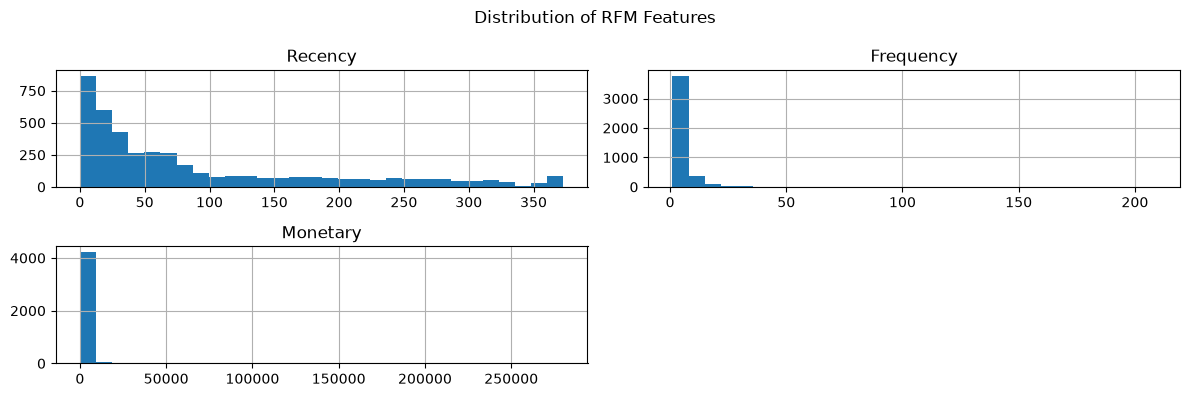

In [75]:
import matplotlib.pyplot as plt

# Visualize the distribution of RFM features
rfm[['Recency', 'Frequency', 'Monetary']].hist(
    bins=30,
    figsize=(12, 4)
)

plt.suptitle('Distribution of RFM Features')
plt.tight_layout()
plt.show()

In [76]:
# Measure skewness of RFM features
rfm[['Recency', 'Frequency', 'Monetary']].skew()

Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64

In [77]:

# Create a copy of the original RFM features
rfm_log = rfm[['Recency', 'Frequency', 'Monetary']].copy()

# Apply logarithmic transformation
rfm_log = np.log1p(rfm_log)

# Display the first five transformed records
rfm_log.head()

,Recency,Frequency,Monetary
0,5.786897,0.693147,11.253955
1,0.693147,2.079442,8.368925
2,4.317488,1.609438,7.494564
3,2.944439,0.693147,7.472245
4,5.736572,0.693147,5.815324


In [78]:
# Compare skewness before and after transformation
skewness_comparison = pd.DataFrame({
    'Original Skewness': rfm[['Recency', 'Frequency', 'Monetary']].skew(),
    'Log-Transformed Skewness': rfm_log.skew()
})

skewness_comparison

,Original Skewness,Log-Transformed Skewness
Recency,1.246048,-0.554566
Frequency,12.067031,1.208652
Monetary,19.339368,0.396599


In [79]:

# Initialize the scaler
scaler = StandardScaler()

# Standardize the log-transformed RFM features
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert the result back into a DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=rfm_log.columns,
    index=rfm_log.index
)

# Display the first five records
rfm_scaled.head()

,Recency,Frequency,Monetary
0,1.409894,-0.955214,3.707716
1,-2.146498,1.074425,1.414903
2,0.383971,0.386304,0.720024
3,-0.574674,-0.955214,0.702287
4,1.374758,-0.955214,-0.614514


In [80]:
# Validate standardized RFM features
print("Feature means:")
print(rfm_scaled.mean())

print("\nFeature standard deviations:")
print(rfm_scaled.std())

Feature means:
Recency     -1.048288e-16
Frequency   -8.189750e-18
Monetary    -3.669008e-16
dtype: float64

Feature standard deviations:
Recency      1.000115
Frequency    1.000115
Monetary     1.000115
dtype: float64


In [81]:
print("RFM scaled dataset shape:", rfm_scaled.shape)
print("Missing values:", rfm_scaled.isna().sum().sum())

RFM scaled dataset shape: (4338, 3)
Missing values: 0


# 3. Feature Engineering – RFM Analysis

## 3.1 RFM Feature Creation

Customer-level RFM features were calculated using qualifying purchase transactions.

**Why RFM was selected:** The source data is transactional, so customer behaviour must first be summarized at customer level. Recency, Frequency, and Monetary capture three complementary dimensions: how recently a customer purchased, how often they purchased, and how much they spent. These measures are directly interpretable by marketing and customer-retention teams and can be calculated consistently from the available invoice, date, quantity, and price fields.

| Feature | Description | Calculation |
|---|---|---|
| Recency | How recently a customer purchased | Days since the customer's latest purchase |
| Frequency | How often a customer purchased | Number of distinct invoices |
| Monetary | How much a customer spent | Total purchase value |

The reference date for Recency was **9 December 2011**, the latest transaction date in the dataset.

The resulting RFM dataset contained:

- 4,338 unique customers.
- 3 customer-level features.
- No missing values.

## 3.2 Distribution Findings

Initial statistical analysis and histograms revealed right-skewed distributions across all three RFM features.

| Feature | Original Skewness | Finding |
|---|---:|---|
| Recency | 1.25 | Moderately right-skewed |
| Frequency | 12.07 | Extremely right-skewed |
| Monetary | 19.34 | Extremely right-skewed |

Frequency and Monetary showed particularly strong skewness, indicating that a small number of customers had substantially higher purchasing activity and spending than most customers.

## 3.3 Data Transformation Decision

A logarithmic transformation using `np.log1p()` was applied to all three RFM features.

This reduced the influence of extreme values and improved the distributions.

| Feature | Original Skewness | After Transformation |
|---|---:|---:|
| Recency | 1.25 | -0.55 |
| Frequency | 12.07 | 1.21 |
| Monetary | 19.34 | 0.40 |

The transformation substantially reduced skewness, particularly for Frequency and Monetary.

**Decision:** Retain the logarithmically transformed features for clustering preparation.

## 3.4 Feature Scaling Decision

`StandardScaler` was applied to the transformed RFM features.

This was necessary because clustering algorithms based on distance calculations can be influenced by differences in feature scales.

Validation confirmed:

- Feature means approximately equal to zero.
- Feature standard deviations approximately equal to one.
- No missing values.

## 3.5 Final Feature Engineering Outcome

The final standardized RFM dataset contains:

| Item | Result |
|---|---:|
| Customers | 4,338 |
| Features | 3 |
| Missing values | 0 |
| Mean after scaling | Approximately 0 |
| Standard deviation | Approximately 1 |

**Final decision:** The standardized RFM dataset is ready for customer segmentation.

The original RFM values will be retained for interpreting customer segments and translating clustering results into meaningful business insights.

In [82]:

# Store the inertia values
inertia_values = []

# Test different numbers of clusters
k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

print("K values:", list(k_values))
print("Inertia values:", inertia_values)

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Inertia values: [6502.133786313935, 4893.252633720077, 3987.6073660910697, 3371.5262199779586, 2896.3641748216046, 2600.7830667676553, 2380.2131169862114, 2201.3452147387566, 2036.2238115928203]


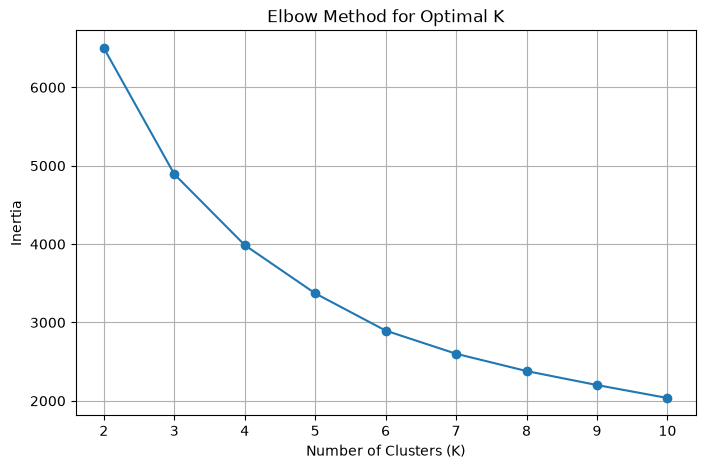

In [83]:
# Plot the Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia_values,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [84]:


silhouette_values = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        cluster_labels
    )

    silhouette_values.append(score)

print("K values:", list(range(2, 11)))
print("Silhouette scores:", silhouette_values)

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Silhouette scores: [0.4343591972869044, 0.3392129038395782, 0.3356589274742927, 0.3149411928961021, 0.3135995039429158, 0.3076939244486073, 0.29408480070024, 0.2761618534028656, 0.27655847338654554]


In [85]:
# Compare cluster sizes for K = 2, 3 and 4

for k in [2, 3, 4]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    print(f"\nNumber of clusters: {k}")
    print(pd.Series(labels).value_counts().sort_index())


Number of clusters: 2
0    2683
1    1655
Name: count, dtype: int64

Number of clusters: 3
0    1688
1     729
2    1921
Name: count, dtype: int64

Number of clusters: 4
0     808
1    1642
2     685
3    1203
Name: count, dtype: int64


In [86]:
# Compare original RFM profiles for K = 2, 3 and 4

for k in [2, 3, 4]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    rfm_comparison = rfm.copy()
    rfm_comparison['Cluster'] = labels

    print(f"\nCustomer profiles for K = {k}")

    display(
        rfm_comparison.groupby('Cluster').agg(
            Customer_Count=('CustomerID', 'count'),
            Avg_Recency=('Recency', 'mean'),
            Avg_Frequency=('Frequency', 'mean'),
            Avg_Monetary=('Monetary', 'mean')
        ).round(2)
    )


Customer profiles for K = 2


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,2683,132.7,1.68,498.22
1,1655,24.8,8.48,4562.22



Customer profiles for K = 3


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,1688,46.26,3.55,1402.13
1,729,12.93,13.67,8016.79
2,1921,161.15,1.34,351.99



Customer profiles for K = 4


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,808,17.06,2.12,540.35
1,1642,179.43,1.32,347.61
2,685,10.39,13.99,8290.35
3,1203,67.80,4.21,1829.55


In [87]:
# Train the final K-Means model with 4 clusters

final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign cluster labels to customers
rfm['Cluster'] = final_kmeans.fit_predict(rfm_scaled)

# Check the number of customers in each cluster
print("Final cluster distribution:")
print(rfm['Cluster'].value_counts().sort_index())

Final cluster distribution:
Cluster
0     808
1    1642
2     685
3    1203
Name: count, dtype: int64


In [88]:
# Attach business-readable segment names while retaining numeric cluster IDs.
# Numeric IDs remain available for reproducibility and later analysis.
segment_names = {
    0: "Recent, Low-Value Customers",
    1: "Less-Recent, Low-Activity Customers",
    2: "High-Value, Frequent Customers",
    3: "Moderate-Activity, Mid-Value Customers"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

print("Customer counts by segment:")
print(rfm["Segment"].value_counts().reindex(segment_names.values()))


Customer counts by segment:
Segment
Recent, Low-Value Customers                808
Less-Recent, Low-Activity Customers       1642
High-Value, Frequent Customers             685
Moderate-Activity, Mid-Value Customers    1203
Name: count, dtype: int64


In [89]:
# Summarize clusters using the original, interpretable RFM measures.
cluster_profiles = rfm.groupby(["Cluster", "Segment"]).agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

cluster_profiles


,,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,Segment,,,,
0,"Recent, Low-Value Customers",808,17.06,2.12,540.35
1,"Less-Recent, Low-Activity Customers",1642,179.43,1.32,347.61
2,"High-Value, Frequent Customers",685,10.39,13.99,8290.35
3,"Moderate-Activity, Mid-Value Customers",1203,67.80,4.21,1829.55


# 4. Customer Segmentation — Modeling Decisions

## 4.1 Why Clustering Was Selected

The business has no existing labels that define customer types. K-Means was therefore selected as an unsupervised method to group customers using their standardized RFM behaviour.

K-Means is computationally practical for this customer-level dataset and produces segment assignments that can be profiled using the original Recency, Frequency, and Monetary measures. Its limitations are also relevant: it is distance-based, sensitive to feature scaling and extreme values, and requires the number of clusters to be selected in advance.

## 4.2 Selecting the Number of Clusters

The Elbow Method and Silhouette Score were used to compare values of K from 2 to 10.

- The Elbow curve suggested a possible bend around K = 4 to K = 6; it did not identify a single unambiguous optimum.
- The highest Silhouette Score occurred at K = 2 (**0.4344**), indicating stronger average separation for two broad groups.
- K = 4 achieved a Silhouette Score of approximately **0.3357**. It was selected because it produced four reasonably sized groups with more useful business differentiation.

**Decision:** Retain K = 4 as a business-oriented compromise, not as the mathematically best-separated solution. The lower silhouette score and overlap between groups should remain visible limitations in the interpretation.

## 4.3 Final Model Configuration

The final model uses:
- Algorithm: K-Means
- Number of clusters: 4
- Random state: 42
- Initializations: 10
- Inputs: log-transformed and standardized Recency, Frequency, and Monetary features

The model assigns each of the **4,338 customers** in the RFM dataset to one of four clusters.

## 4.4 Customer Segment Profiles

The table below reports averages in the original RFM units. Recency is measured in days; Frequency is the number of distinct invoices; Monetary is total recorded purchase value in pounds sterling (GBP).

| Cluster | Segment name | Customers | Avg. Recency (days) | Avg. Frequency (invoices) | Avg. Monetary |
|---:|---|---:|---:|---:|---:|
| 0 | Recent, Low-Value Customers | 808 | 17.06 | 2.12 | 540.35 |
| 1 | Less-Recent, Low-Activity Customers | 1,642 | 179.43 | 1.32 | 347.61 |
| 2 | High-Value, Frequent Customers | 685 | 10.39 | 13.99 | 8,290.35 |
| 3 | Moderate-Activity, Mid-Value Customers | 1,203 | 67.80 | 4.21 | 1,829.55 |

**Naming rationale:** Segment names describe the observed RFM profile. The term *loyal* is avoided because frequency and spend alone do not prove attitudinal loyalty or long-term retention.

## 4.5 Business Interpretation and Potential Actions

| Segment | Evidence-based interpretation | Potential management action |
|---|---|---|
| Recent, Low-Value Customers | Purchased recently, but have relatively low invoice frequency and spend. | Encourage a second purchase with relevant cross-sell suggestions or a time-limited introductory offer. |
| Less-Recent, Low-Activity Customers | Largest group; longest average recency and lowest average frequency and spend. | Test reactivation campaigns and monitor response before allocating large incentives. |
| High-Value, Frequent Customers | Smallest group, with the highest average frequency and monetary value and very recent purchases. | Prioritize retention, service quality, early access, and carefully selected complementary products. |
| Moderate-Activity, Mid-Value Customers | Intermediate recency, frequency, and spend. | Encourage repeat purchases and test category-based recommendations to increase basket value. |

These are proposed actions, not measured campaign outcomes. Campaign performance should be validated through response, conversion, and incremental-revenue tests.


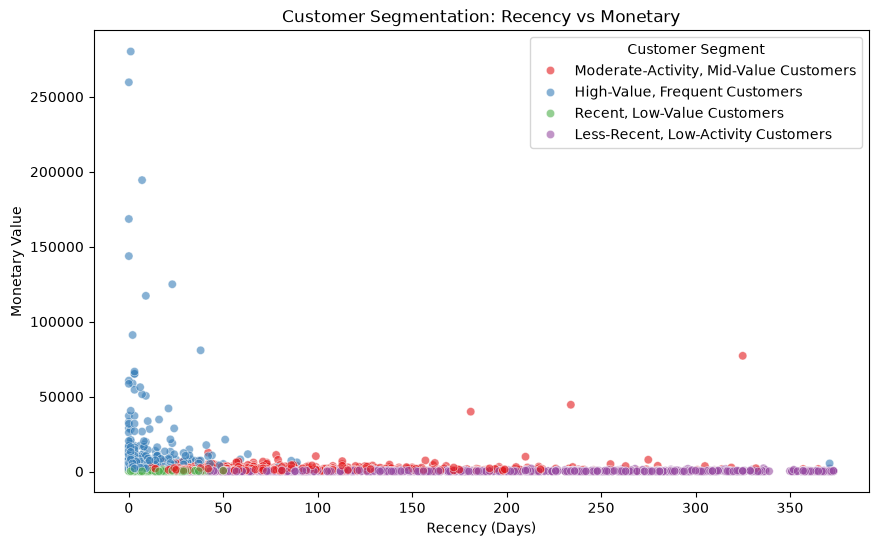

In [90]:

# Visualize customer segments
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Segment',
    palette='Set1',
    alpha=0.6
)

plt.title('Customer Segmentation: Recency vs Monetary')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value')
plt.legend(title='Customer Segment')

plt.show()

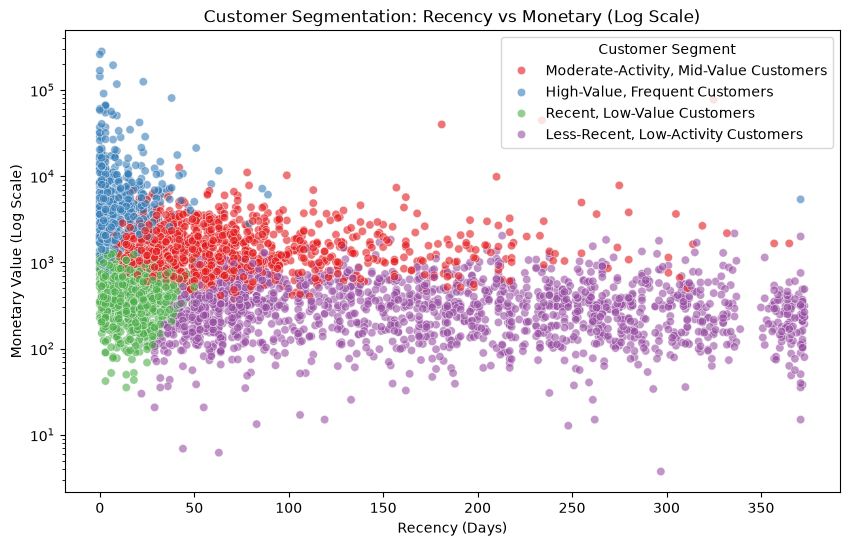

In [91]:
# Customer segmentation with logarithmic Monetary axis

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Segment',
    palette='Set1',
    alpha=0.6
)

plt.yscale('log')

plt.title('Customer Segmentation: Recency vs Monetary (Log Scale)')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value (Log Scale)')
plt.legend(title='Customer Segment')

plt.show()

### Customer Segmentation: Recency vs Monetary

A scatter plot was created to visualize the four customer segments using Recency and Monetary values.

The initial visualization showed that extreme spending values compressed most customers near the bottom of the chart. A logarithmic scale was therefore applied to the Monetary axis to improve readability.

**Key findings:**

- Cluster 0 contains recently active customers with relatively low spending.
- Cluster 1 contains customers with lower purchasing activity and generally longer periods since their last purchase.
- Cluster 2 contains recently active, high-spending customers.
- Cluster 3 represents customers with intermediate purchasing behaviour and moderate-to-high spending.

The visualization supports the differences identified in the RFM cluster profiles. However, some overlap remains between clusters.

**Decision:** Retain the four-cluster model and use additional visualizations, including PCA, to examine cluster separation from another perspective.

Note: The logarithmic scale was used for visualization only. Original Monetary values were retained for business interpretation.

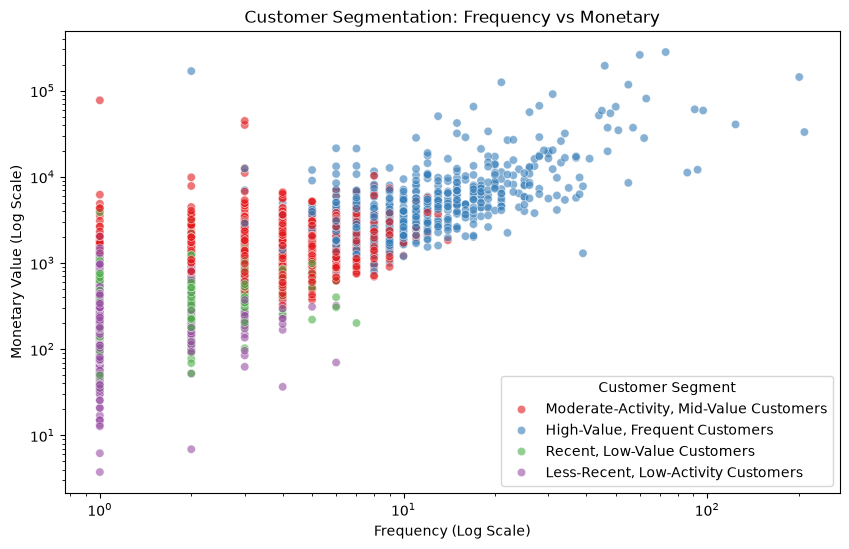

In [92]:
# Visualize Frequency vs Monetary by customer cluster

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Segment',
    palette='Set1',
    alpha=0.6
)

plt.xscale('log')
plt.yscale('log')

plt.title('Customer Segmentation: Frequency vs Monetary')
plt.xlabel('Frequency (Log Scale)')
plt.ylabel('Monetary Value (Log Scale)')
plt.legend(title='Customer Segment')

plt.show()

### Customer Segmentation: Frequency vs Monetary

A scatter plot was created to examine the relationship between customer purchase frequency and total spending. Logarithmic scales were applied to both axes to improve visualization of the wide range of values.

**Key findings:**

- Cluster 0 generally contains customers with low purchase frequency and relatively low spending.
- Cluster 1 contains customers with low purchasing activity and generally lower spending.
- Cluster 2 is distinguished by higher purchase frequency and substantially higher monetary value.
- Cluster 3 represents customers with intermediate purchasing behaviour and spending.

The visualization suggests a positive relationship between purchase frequency and monetary value.

Some overlap remains between customer groups, particularly among customers with lower purchase frequencies.

**Decision:** Retain the four-cluster segmentation model for further analysis. Use the RFM profiles alongside visualizations when interpreting customer segments.

In [93]:


# Initialize PCA with two components
pca = PCA(n_components=2)

# Transform the standardized RFM features
rfm_pca = pca.fit_transform(rfm_scaled)

# Display explained variance
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal explained variance:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.75090484 0.18786137]

Total explained variance:
0.9387662118893707


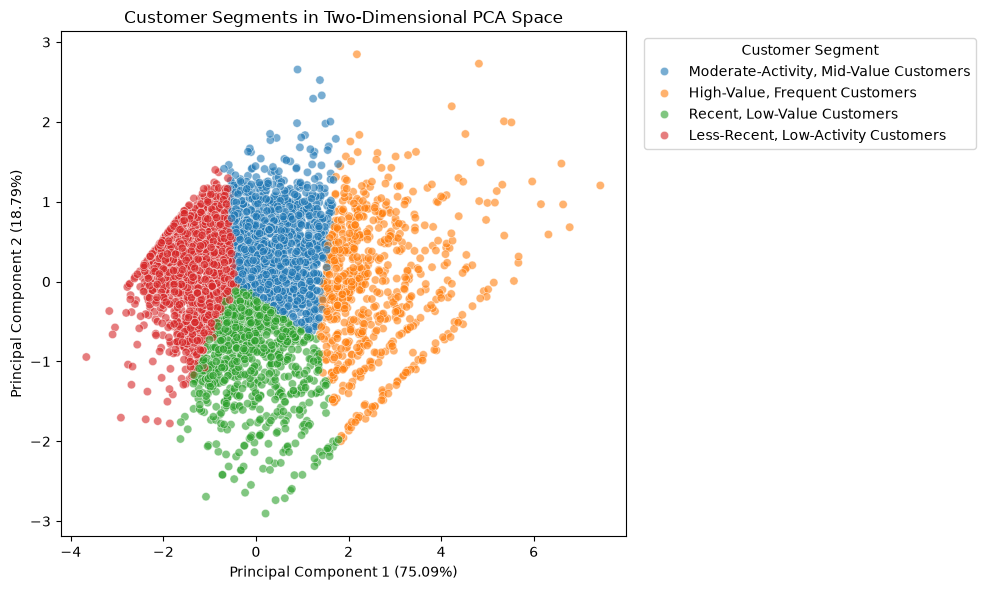

In [94]:
# Keep the numeric cluster ID and add a business-readable segment label.
rfm_pca_df = pd.DataFrame(
    rfm_pca,
    columns=["PC1", "PC2"],
    index=rfm.index
)

rfm_pca_df["Cluster"] = rfm["Cluster"].values
rfm_pca_df["Segment"] = rfm["Segment"].values

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm_pca_df,
    x="PC1",
    y="PC2",
    hue="Segment",
    alpha=0.6
)

plt.title("Customer Segments in Two-Dimensional PCA Space")
plt.xlabel("Principal Component 1 (75.09%)")
plt.ylabel("Principal Component 2 (18.79%)")
plt.legend(title="Customer Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


# 5. PCA Analysis

## 5.1 Purpose of PCA

Principal Component Analysis (PCA) was applied to the standardized RFM features to represent the three-dimensional customer data in two dimensions for visualization.

PCA is not the clustering algorithm and does not create the customer groups. The K-Means model was fitted using all three standardized RFM features; PCA is used afterward to inspect how the assigned segments are distributed in a two-dimensional view.

## 5.2 Explained Variance

| Component | Explained variance |
|---|---:|
| PC1 | 75.09% |
| PC2 | 18.79% |
| **Combined** | **93.88%** |

The first two components retain approximately **93.88%** of the variance in the standardized RFM features. This makes the two-dimensional plot a useful summary of the feature variation, although some information is necessarily lost.

## 5.3 Interpretation

The PCA scatter plot shows visible structure among the four segments, with some overlap in the central area. This is consistent with the moderate silhouette score: the groups are useful for business profiling, but they are not perfectly separated.

The component axes are weighted combinations of the original RFM variables. Their directions should not be interpreted as direct Recency, Frequency, or Monetary axes without examining the PCA loadings.

## 5.4 Decision

Retain the two-component PCA view as a visualization aid. Keep the K-Means assignments based on the original three standardized RFM features. Use the RFM profile table—not the PCA plot alone—to explain the business meaning of each segment.


In [95]:
# Prepare valid product purchase records for Market Basket Analysis

df_market_basket = df_no_duplicates[
    (df_no_duplicates['Quantity'] > 0) &
    (df_no_duplicates['UnitPrice'] > 0) &
    (df_no_duplicates['PurchaseValue'] > 0) &
    (df_no_duplicates['Description'].notna())
].copy()

print("Market Basket Analysis dataset:", df_market_basket.shape)
print("Unique invoices:", df_market_basket['InvoiceNo'].nunique())
print("Unique products:", df_market_basket['Description'].nunique())

Market Basket Analysis dataset: (524878, 9)
Unique invoices: 19960
Unique products: 4026


In [96]:
# Check repeated product descriptions within invoices

invoice_product_duplicates = df_market_basket.duplicated(
    subset=['InvoiceNo', 'Description']
).sum()

print(
    "Repeated invoice-product combinations:",
    invoice_product_duplicates
)

Repeated invoice-product combinations: 5460


In [97]:
df_basket_unique = df_market_basket[
    ['InvoiceNo', 'Description']
].drop_duplicates()

print("Original product records:", len(df_market_basket))
print("Unique invoice-product combinations:", len(df_basket_unique))
print("Unique invoices:", df_basket_unique['InvoiceNo'].nunique())
print("Unique products:", df_basket_unique['Description'].nunique())

Original product records: 524878
Unique invoice-product combinations: 519418
Unique invoices: 19960
Unique products: 4026


In [98]:
from mlxtend.preprocessing import TransactionEncoder

# Group products by invoice
grouped_transactions = (
    df_basket_unique.groupby('InvoiceNo')['Description'].apply(list)
)

# Convert invoices into a transaction list
transactions = grouped_transactions.tolist()

# Encode transactions as a sparse one-hot matrix
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions, sparse=True)

# Create the basket matrix
basket_matrix = pd.DataFrame.sparse.from_spmatrix(
    te_array,
    index=grouped_transactions.index,
    columns=te.columns_
)

print("Basket matrix shape:", basket_matrix.shape)
print("Number of invoices:", basket_matrix.shape[0])
print("Number of products:", basket_matrix.shape[1])

Basket matrix shape: (19960, 4026)
Number of invoices: 19960
Number of products: 4026


In [99]:
items_per_invoice = basket_matrix.sum(axis=1)

print("Minimum:", items_per_invoice.min())
print("Maximum:", items_per_invoice.max())
print("Average:", items_per_invoice.mean())
print("Missing values:", basket_matrix.isna().sum().sum())

Minimum: 1
Maximum: 1108
Average: 26.022945891783568
Missing values: 0


In [100]:


frequent_itemsets = apriori(
    basket_matrix,
    min_support=0.01,
    use_colnames=True
)

print("Frequent itemsets:", len(frequent_itemsets))
frequent_itemsets.head(10)

Frequent itemsets: 1902


,support,itemsets
0,0.013477,frozenset({ SET 2 TEA TOWELS I LOVE LONDON })
1,0.015932,frozenset({10 COLOUR SPACEBOY PEN})
2,0.012575,frozenset({12 MESSAGE CARDS WITH ENVELOPES})
3,0.017786,frozenset({12 PENCIL SMALL TUBE WOODLAND})
4,0.018136,frozenset({12 PENCILS SMALL TUBE RED RETROSPOT})
5,0.017786,frozenset({12 PENCILS SMALL TUBE SKULL})
6,0.013427,frozenset({12 PENCILS TALL TUBE RED RETROSPOT})
7,0.012826,frozenset({12 PENCILS TALL TUBE SKULLS})
8,0.012475,frozenset({12 PENCILS TALL TUBE WOODLAND})
9,0.013076,frozenset({15CM CHRISTMAS GLASS BALL 20 LIGHTS})


In [101]:
frequent_itemsets['item_count'] = frequent_itemsets['itemsets'].apply(len)

print(frequent_itemsets['item_count'].value_counts().sort_index())

item_count
1    810
2    840
3    233
4     18
5      1
Name: count, dtype: int64


In [102]:

rules = association_rules(
    frequent_itemsets.drop(columns='item_count'),
    metric='confidence',
    min_threshold=0.3
)

print("Number of association rules:", len(rules))

Number of association rules: 1824


In [103]:
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values(
    by='lift', ascending=False
).head(10)

,antecedents,consequents,support,confidence,lift
1061,"frozenset({HERB MARKER PARSLEY, HERB MARKER RO...",frozenset({HERB MARKER THYME}),0.010170,0.944186,79.518791
1062,frozenset({HERB MARKER THYME}),"frozenset({HERB MARKER PARSLEY, HERB MARKER RO...",0.010170,0.856540,79.518791
1064,frozenset({HERB MARKER ROSEMARY}),"frozenset({HERB MARKER THYME, HERB MARKER PARS...",0.010170,0.845833,79.262128
1059,"frozenset({HERB MARKER THYME, HERB MARKER PARS...",frozenset({HERB MARKER ROSEMARY}),0.010170,0.953052,79.262128
1053,"frozenset({HERB MARKER THYME, HERB MARKER BASIL})",frozenset({HERB MARKER ROSEMARY}),0.010020,0.952381,79.206349
1058,frozenset({HERB MARKER ROSEMARY}),"frozenset({HERB MARKER THYME, HERB MARKER BASIL})",0.010020,0.833333,79.206349
1055,"frozenset({HERB MARKER BASIL, HERB MARKER ROSE...",frozenset({HERB MARKER THYME}),0.010020,0.934579,78.709728
1056,frozenset({HERB MARKER THYME}),"frozenset({HERB MARKER BASIL, HERB MARKER ROSE...",0.010020,0.843882,78.709728
293,frozenset({HERB MARKER ROSEMARY}),frozenset({HERB MARKER THYME}),0.011072,0.920833,77.552039
292,frozenset({HERB MARKER THYME}),frozenset({HERB MARKER ROSEMARY}),0.011072,0.932489,77.552039


In [104]:
# Create a display-only copy so the original rule sets remain usable for recommendation logic.
rules_display = rules.copy()

rules_display["antecedents"] = rules_display["antecedents"].apply(
    lambda items: ", ".join(sorted(items))
)
rules_display["consequents"] = rules_display["consequents"].apply(
    lambda items: ", ".join(sorted(items))
)

rules_display[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].sort_values(by="lift", ascending=False).head(10)


,antecedents,consequents,support,confidence,lift
1061,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010170,0.944186,79.518791
1062,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.010170,0.856540,79.518791
1064,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.010170,0.845833,79.262128
1059,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010170,0.953052,79.262128
1053,"HERB MARKER BASIL, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010020,0.952381,79.206349
1058,HERB MARKER ROSEMARY,"HERB MARKER BASIL, HERB MARKER THYME",0.010020,0.833333,79.206349
1055,"HERB MARKER BASIL, HERB MARKER ROSEMARY",HERB MARKER THYME,0.010020,0.934579,78.709728
1056,HERB MARKER THYME,"HERB MARKER BASIL, HERB MARKER ROSEMARY",0.010020,0.843882,78.709728
293,HERB MARKER ROSEMARY,HERB MARKER THYME,0.011072,0.920833,77.552039
292,HERB MARKER THYME,HERB MARKER ROSEMARY,0.011072,0.932489,77.552039


In [105]:
# Retain rules with strong conditional confidence and positive lift.
strong_rules = rules[
    (rules["confidence"] >= 0.70) &
    (rules["lift"] > 1)
].copy()

strong_rules_display = strong_rules.copy()
strong_rules_display["antecedents"] = strong_rules_display["antecedents"].apply(
    lambda items: ", ".join(sorted(items))
)
strong_rules_display["consequents"] = strong_rules_display["consequents"].apply(
    lambda items: ", ".join(sorted(items))
)

strong_rules_display[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].sort_values(by="support", ascending=False).head(10)


,antecedents,consequents,support,confidence,lift
244,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.038427,0.720188,14.190472
243,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.038427,0.757157,14.190472
239,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.031663,0.826144,16.278213
639,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.029960,0.781699,14.650440
232,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.027355,0.720317,15.747557
1027,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.027104,0.856013,16.043204
1028,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.027104,0.904682,17.825724
1031,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.027104,0.707190,18.403524
1026,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.027104,0.705346,18.403524
106,CHARLOTTE BAG PINK POLKADOT,RED RETROSPOT CHARLOTTE BAG,0.026152,0.703504,13.606532


In [106]:
frequent_itemsets[
    frequent_itemsets['item_count'] == 2
].sort_values(
    by='support', ascending=False
).head(10)

,support,itemsets,item_count
1193,0.041333,"frozenset({JUMBO BAG PINK POLKADOT, JUMBO BAG ...",2
1037,0.038427,"frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...",2
1237,0.036273,"frozenset({JUMBO STORAGE BAG SUKI, JUMBO BAG R...",2
1235,0.034068,"frozenset({JUMBO BAG RED RETROSPOT, JUMBO SHOP...",2
1355,0.032114,"frozenset({LUNCH BAG BLACK SKULL., LUNCH BAG ...",2
843,0.032064,"frozenset({ALARM CLOCK BAKELIKE RED , ALARM CL...",2
1031,0.031663,"frozenset({GREEN REGENCY TEACUP AND SAUCER, PI...",2
1411,0.030361,"frozenset({LUNCH BAG PINK POLKADOT, LUNCH BAG ...",2
1533,0.029960,"frozenset({ROSES REGENCY TEACUP AND SAUCER , P...",2
1124,0.029309,"frozenset({JUMBO BAG BAROQUE BLACK WHITE, JUM...",2


## 6. Market Basket Analysis

### 6.1 Business Objective

Market Basket Analysis identifies products that appear together in the same invoice. The objective is to identify potential cross-selling, product-display, and bundle opportunities—not to prove that one product causes the purchase of another.

### 6.2 Data Preparation and Rationale

A separate invoice-level dataset, `df_market_basket`, was created from valid purchase records. It includes records with positive quantity, positive unit price, positive purchase value, and a non-missing product description. Cancelled invoices were already excluded from the cleaned transaction base.

Customer IDs are not required for this analysis because the unit of analysis is the invoice, not the individual customer.

Repeated invoice–product combinations were removed so that each product is represented once per invoice. This matches the presence/absence definition used by the basket matrix; quantity is not used in this association analysis.

| Measure | Result |
|---|---:|
| Valid product records | 524,878 |
| Unique invoice–product combinations | 519,418 |
| Repeated combinations removed | 5,460 |
| Unique invoices | 19,960 |
| Unique products | 4,026 |

### 6.3 Basket Matrix

The transaction data was encoded as a sparse matrix:

- Rows represent invoices.
- Columns represent product descriptions.
- A `True` value indicates that a product appeared on the invoice; `False` indicates that it did not.

The matrix contains **19,960 invoices and 4,026 products**. A sparse representation is appropriate because most products do not occur in most invoices and it reduces memory use.

The observed basket size ranges from 1 to 1,108 unique products per invoice, with an average of approximately 26.02. The maximum is unusually large relative to the average and should be inspected before operational use; unusually large invoices can have disproportionate influence on co-occurrence patterns.

### 6.4 Apriori and Association Rules

Apriori was run with **minimum support = 1%**. An itemset must therefore appear in at least 1% of invoices to be retained. This threshold limits the analysis to patterns with a minimum level of prevalence, but it can exclude niche combinations.

The analysis identified **1,902 frequent itemsets**:

| Itemset size | Number of itemsets |
|---|---:|
| 1 product | 810 |
| 2 products | 840 |
| 3 products | 233 |
| 4 products | 18 |
| 5 products | 1 |
| **Total** | **1,902** |

Association rules were generated with **minimum confidence = 30%**, producing **1,824 rules**.

The measures are interpreted together:
- **Support** is the proportion of invoices containing the complete itemset.
- **Confidence** is the proportion of invoices containing the antecedent that also contain the consequent.
- **Lift** compares the observed co-occurrence with the co-occurrence expected if the items were independent. A lift above 1 indicates a positive association.

### 6.5 Key Purchasing Patterns

The strongest high-support patterns include:

**Regency teacup collection**
- Green Regency Teacup and Saucer → Roses Regency Teacup and Saucer
- Support: **3.84%**
- Confidence: **75.72%**
- Lift: **14.19**

This suggests an opportunity to display matching designs together or recommend the complementary design on the product page.

**Jumbo storage bags**
Different jumbo bag designs frequently appear in the same invoice. The highest-support pair in the selected results had approximately **4.13% support**. Related designs could be grouped in merchandising displays or cross-sell placements.

**Lunch bags**
Different lunch bag designs also appear together. The retailer could test recommendations for related designs, while monitoring whether these suggestions add incremental purchases.

**Gardeners' kneeling pads**
- Gardeners Kneeling Pad Cup of Tea → Gardeners Kneeling Pad Keep Calm
- Support: **2.74%**
- Confidence: **72.03%**
- Lift: **15.75**

This association could support a related-product display or a small bundle test.

### 6.6 Business Actions

| Pattern | Potential action | How to measure |
|---|---|---|
| Regency teacup designs | Show matching designs together and test a collection bundle. | Bundle conversion and average order value. |
| Jumbo bag designs | Add complementary bag recommendations to product pages. | Recommendation click-through and attach rate. |
| Lunch bag designs | Test related-design cross-sells. | Incremental units per order. |
| Gardeners' kneeling pads | Place related designs together and test a bundle. | Bundle take-up and margin per order. |

### 6.7 Limitations

- Association does not establish causation or prove that a recommendation will lead to another purchase.
- A high lift can occur for a relatively uncommon combination; support and confidence should also be considered.
- The 1% support threshold may exclude useful niche combinations.
- Invoice-level patterns do not reveal customer-specific preferences.
- Product descriptions may contain variants or inconsistent naming.
- The unusually large maximum basket size should be reviewed for data quality and business context before the rules are deployed.

**Decision:** Treat the rules as hypotheses for merchandising and cross-selling experiments. Validate their commercial value with controlled tests before making permanent changes.


## 7. Customer-Level Product Recommendation Demonstration

This section demonstrates how association rules can be applied to one selected customer from the high-value, frequent-purchasing segment.

The example uses the customer's observed purchase history and the full-period association rules to illustrate the recommendation logic. **It is a demonstration, not the time-based model evaluation.** The separate evaluation later in this notebook rebuilds rules and popularity rankings from the training period only to avoid using future transactions when generating test recommendations.

A rule is eligible only when **all products in its antecedent** are present in the customer's purchase history. Products already purchased by the customer are excluded from the recommendation list. Candidates are ranked by their highest applicable rule confidence; this ranking score is a rule statistic, not a calibrated probability that the individual customer will buy the item.


In [107]:
customer_id = rfm[rfm['Cluster'] == 2].sort_values(
    'Frequency', ascending=False
).iloc[0]['CustomerID']

print("Selected Customer:", customer_id)

Selected Customer: 12748.0


In [108]:
customer_purchases = df_rfm_transactions[
    df_rfm_transactions['CustomerID'] == customer_id
]

print("Number of invoices:", customer_purchases['InvoiceNo'].nunique())
print("Number of products:", customer_purchases['Description'].nunique())

customer_purchases['Description'].value_counts().head(10)

Number of invoices: 209
Number of products: 1778


Description
REX CASH+CARRY JUMBO SHOPPER        33
POPCORN HOLDER                      17
PAPER CHAIN KIT 50'S CHRISTMAS      15
JAZZ HEARTS PURSE NOTEBOOK          15
MODERN FLORAL STATIONERY SET        15
Manual                              14
LUNCH BAG SPACEBOY DESIGN           14
LUNCH BAG  BLACK SKULL.             14
SET OF 4 PANTRY JELLY MOULDS        13
PLASTERS IN TIN WOODLAND ANIMALS    12
Name: count, dtype: int64

In [109]:
purchased_products = set(customer_purchases['Description'])

print("Previously purchased products:", len(purchased_products))

Previously purchased products: 1778


In [110]:
rules_raw = association_rules(
    frequent_itemsets.drop(columns='item_count'),
    metric='confidence',
    min_threshold=0.3
)

customer_rules = rules_raw[
    rules_raw['antecedents'].apply(
        lambda x: x.issubset(purchased_products)
    )
]

print("Matching customer rules:", len(customer_rules))


Matching customer rules: 1657


In [111]:
recommended_products = []

for _, row in customer_rules.iterrows():
    for product in row['consequents']:
        if product not in purchased_products:
            recommended_products.append(product)

print("Potential recommendations:", len(set(recommended_products)))

Potential recommendations: 12


In [112]:
recommendation_scores = {}

for _, row in customer_rules.iterrows():
    for product in row['consequents']:
        if product not in purchased_products:
            recommendation_scores[product] = max(
                recommendation_scores.get(product, 0),
                row['confidence']
            )

top_5 = sorted(
    recommendation_scores.items(),
    key=lambda x: x[1],
    reverse=True
)[:5]

top_5

[('DOTCOM POSTAGE', 0.9587155963302753),
 ('JAM JAR WITH PINK LID', 0.741830065359477),
 ('PINK POLKADOT BOWL', 0.6459627329192547),
 ('RED STRIPE CERAMIC DRAWER KNOB', 0.5882352941176471),
 ('RED SPOT CERAMIC DRAWER KNOB', 0.5508021390374331)]

In [113]:
recommendation_scores.pop('DOTCOM POSTAGE', None)

top_5 = sorted(
    recommendation_scores.items(),
    key=lambda x: x[1],
    reverse=True
)[:5]

top_5

[('JAM JAR WITH PINK LID', 0.741830065359477),
 ('PINK POLKADOT BOWL', 0.6459627329192547),
 ('RED STRIPE CERAMIC DRAWER KNOB', 0.5882352941176471),
 ('RED SPOT CERAMIC DRAWER KNOB', 0.5508021390374331),
 ('WHITE SPOT BLUE CERAMIC DRAWER KNOB', 0.5481283422459894)]

### Cold-Start Problem

A new customer has no purchase history, so the personalized association-rule component cannot identify an individual preference profile. This is the **user cold-start problem**.

The project addresses this with a popularity-based fallback: recommend products that appear in the largest number of training-period invoices. For a new customer, the fallback can provide an initial list without requiring a CustomerID purchase history.

This is a general fallback, not a personalized prediction. A future production version could ask customers about their interests, use product-category browsing, or incorporate content-based recommendations.

### Hybrid Recommendation System — Implemented Approach

The project implements a two-source hybrid recommendation workflow:

1. **Personalized association-rule recommendations:** Match rules whose complete antecedent is present in the customer's purchase history, then rank unseen consequent products by the maximum applicable confidence.
2. **Popular-product fallback:** If fewer than five personalized products are available, fill the remaining positions with products ranked by the number of distinct training invoices containing them.

**Existing customers:** Use personalized association-rule candidates first; popular products fill any remaining slots. Products already present in the customer's training history are excluded.

**New customers:** Use the popular-product list because no purchase history is available. The current offline evaluation does not measure new-customer performance because it evaluates customers who appear in both the training and testing periods.

**Important scope clarification:** Market Basket Analysis provides the association rules used by the personalized component; it is not a third independently scored recommender in the final implementation. The evaluated hybrid therefore combines association-rule recommendations and popularity fallback.

**Ranking limitation:** Rule candidates are ranked by maximum confidence. Popularity is used as a fallback rather than blended into a single calibrated score. The confidence value is a property of the rule in the training data, not an individual purchase probability.


### Hybrid Recommendation System

The project implements a hybrid recommendation approach that combines personalized association-rule recommendations with a popularity-based fallback.

The objective is to provide relevant product suggestions for customers with different levels of purchase history while addressing the cold-start problem.

#### 1. Personalized Association-Rule Recommendations

- Uses the customer's previous purchase history to identify relevant products.
- Applies association rules discovered through Market Basket Analysis.
- Generates recommendations based on products frequently purchased together.
- Excludes products the customer has already purchased.

#### 2. Popular-Product Fallback

- Uses popular products ranked by the number of distinct invoices in which they appear.
- Fills recommendation positions when personalized recommendations are insufficient.
- Provides a general recommendation approach for customers without purchase history.

#### How the Hybrid System Works

| Customer Type | Recommendation Approach |
|---|---|
| Existing customers | Personalized association-rule recommendations, supplemented by popular products when needed. |
| New customers | Popular-product recommendations because individual purchase history is unavailable. |
| Customers with limited history | Uses available purchase information and popular-product fallback. |

#### Implementation and Evaluation Considerations

- Association-rule confidence is used to rank personalized recommendation candidates.
- Popularity is used to fill remaining recommendation positions; it is not combined with confidence into a single scoring formula.
- The formal evaluation uses a chronological train-test split and includes 1,893 returning customers who appear in both periods.
- New-customer recommendations are demonstrated separately and are not included in the formal evaluation.
- The evaluation results measure offline recommendation performance, not actual customer purchases or incremental sales.

#### Conclusion

The implemented hybrid recommendation approach combines customer-level purchasing patterns with overall product popularity. It provides personalized recommendations where sufficient purchase information is available and uses popular products as a fallback when customer history is limited or unavailable.

### Popular-Product Fallback Demonstration

The following popularity list illustrates the fallback using the full cleaned purchase dataset. The formal time-based evaluation below separately calculates popularity from the training period only; this separation prevents test-period information from influencing evaluation recommendations.


In [114]:
popular_products = (
    df_market_basket.groupby('Description')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
)

popular_products = popular_products.drop(
    ['DOTCOM POSTAGE', 'Manual'], errors='ignore'
)

popular_products.head(10)

Description
WHITE HANGING HEART T-LIGHT HOLDER    2256
JUMBO BAG RED RETROSPOT               2089
REGENCY CAKESTAND 3 TIER              1988
PARTY BUNTING                         1685
LUNCH BAG RED RETROSPOT               1564
ASSORTED COLOUR BIRD ORNAMENT         1455
SET OF 3 CAKE TINS PANTRY DESIGN      1385
PACK OF 72 RETROSPOT CAKE CASES       1320
LUNCH BAG  BLACK SKULL.               1273
NATURAL SLATE HEART CHALKBOARD        1249
Name: InvoiceNo, dtype: int64

In [115]:
popular_product_list = popular_products.head(10).index.tolist()

print(popular_product_list)

['WHITE HANGING HEART T-LIGHT HOLDER', 'JUMBO BAG RED RETROSPOT', 'REGENCY CAKESTAND 3 TIER', 'PARTY BUNTING', 'LUNCH BAG RED RETROSPOT', 'ASSORTED COLOUR BIRD ORNAMENT', 'SET OF 3 CAKE TINS PANTRY DESIGN ', 'PACK OF 72 RETROSPOT CAKE CASES', 'LUNCH BAG  BLACK SKULL.', 'NATURAL SLATE HEART CHALKBOARD ']


In [116]:
new_customer_recommendations = popular_product_list[:5]

print(new_customer_recommendations)

['WHITE HANGING HEART T-LIGHT HOLDER', 'JUMBO BAG RED RETROSPOT', 'REGENCY CAKESTAND 3 TIER', 'PARTY BUNTING', 'LUNCH BAG RED RETROSPOT']


In [117]:
# Start with the association-rule recommendations
hybrid_recommendations = [
    product for product, score in top_5
]

# Add popular products if fewer than 5 recommendations exist
for product in popular_product_list:
    if len(hybrid_recommendations) == 5:
        break

    if (product not in purchased_products and
            product not in hybrid_recommendations):
        hybrid_recommendations.append(product)

print(hybrid_recommendations)

['JAM JAR WITH PINK LID', 'PINK POLKADOT BOWL', 'RED STRIPE CERAMIC DRAWER KNOB', 'RED SPOT CERAMIC DRAWER KNOB', 'WHITE SPOT BLUE CERAMIC DRAWER KNOB']


In [118]:
for product in hybrid_recommendations:
    print(product, "Already purchased:", product in purchased_products)

JAM JAR WITH PINK LID Already purchased: False
PINK POLKADOT BOWL Already purchased: False
RED STRIPE CERAMIC DRAWER KNOB Already purchased: False
RED SPOT CERAMIC DRAWER KNOB Already purchased: False
WHITE SPOT BLUE CERAMIC DRAWER KNOB Already purchased: False


In [119]:
recommendation_results = pd.DataFrame({
    'Product': hybrid_recommendations,
    'Confidence': [
        recommendation_scores[product]
        if product in recommendation_scores else None
        for product in hybrid_recommendations
    ]
})

recommendation_results['Confidence'] = (
    recommendation_results['Confidence'] * 100
).round(2)

recommendation_results

,Product,Confidence
0,JAM JAR WITH PINK LID,74.18
1,PINK POLKADOT BOWL,64.60
2,RED STRIPE CERAMIC DRAWER KNOB,58.82
3,RED SPOT CERAMIC DRAWER KNOB,55.08
4,WHITE SPOT BLUE CERAMIC DRAWER KNOB,54.81


In [120]:
# Find the first and last transaction dates
start_date = df_market_basket['InvoiceDate'].min()
end_date = df_market_basket['InvoiceDate'].max()

# Set the cutoff date at 80% of the time period
cutoff_date = start_date + (end_date - start_date) * 0.8

# Split the transactions
train_data = df_market_basket[
    df_market_basket['InvoiceDate'] <= cutoff_date
].copy()

test_data = df_market_basket[
    df_market_basket['InvoiceDate'] > cutoff_date
].copy()

print("Cutoff date:", cutoff_date)
print("Training transactions:", len(train_data))
print("Testing transactions:", len(test_data))

Cutoff date: 2011-09-25 21:33:12
Training transactions: 349050
Testing transactions: 175828


In [121]:
# Keep one product per invoice
train_basket = train_data[
    ['InvoiceNo', 'Description']
].drop_duplicates()

# Group products by invoice
train_transactions = (
    train_basket.groupby('InvoiceNo')['Description'].apply(list)
)

print("Training invoices:", len(train_transactions))
print("Unique products:", train_basket['Description'].nunique())

Training invoices: 13922
Unique products: 3794


In [122]:

te = TransactionEncoder()

te_array = te.fit(train_transactions).transform(
    train_transactions,
    sparse=True
)

train_basket_matrix = pd.DataFrame.sparse.from_spmatrix(
    te_array,
    index=train_transactions.index,
    columns=te.columns_
)

print("Basket matrix shape:", train_basket_matrix.shape)

Basket matrix shape: (13922, 3794)


In [123]:

train_itemsets = apriori(
    train_basket_matrix,
    min_support=0.01,
    use_colnames=True
)

print("Frequent itemsets:", len(train_itemsets))

Frequent itemsets: 2048


In [124]:

train_rules = association_rules(
    train_itemsets,
    metric='confidence',
    min_threshold=0.30
)

print("Association rules:", len(train_rules))

Association rules: 2538


In [125]:
# Keep transactions with known customers
train_customers = train_data[
    train_data['CustomerID'].notna()
].copy()

# Group purchased products by customer
customer_history = (
    train_customers.groupby('CustomerID')['Description']
    .apply(set)
)

print("Customers in training data:", len(customer_history))

Customers in training data: 3550


In [126]:
# Keep transactions with known customers
test_customers = test_data[
    test_data['CustomerID'].notna()
].copy()

# Group actual purchases by customer
actual_purchases = (
    test_customers.groupby('CustomerID')['Description']
    .apply(set)
)

print("Customers in testing data:", len(actual_purchases))

Customers in testing data: 2681


In [127]:
# Find customers present in both periods
common_customers = set(customer_history.index) & set(actual_purchases.index)

print("Customers in both periods:", len(common_customers))

Customers in both periods: 1893


In [128]:
customer_recommendations = {}

for customer in common_customers:

    purchased = customer_history[customer]

    matching_rules = train_rules[
        train_rules['antecedents'].apply(
            lambda x: x.issubset(purchased)
        )
    ]

    scores = {}

    for _, row in matching_rules.iterrows():
        for product in row['consequents']:

            if product not in purchased:
                scores[product] = max(
                    scores.get(product, 0),
                    row['confidence']
                )

    top_products = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:5]

    customer_recommendations[customer] = [
        product for product, score in top_products
    ]

print("Customers evaluated:", len(customer_recommendations))

Customers evaluated: 1893


In [129]:
# Evaluate the association-rule baseline across every customer in the common test cohort.
baseline_precision_at_5 = []
baseline_recall_at_5 = []

for customer in common_customers:
    recommended = set(customer_recommendations[customer])
    actual = actual_purchases[customer]
    correct = recommended.intersection(actual)

    # Fixed denominator of five keeps the baseline comparable with the hybrid system.
    baseline_precision_at_5.append(len(correct) / 5)

    # Count how much of the customer's later unique-product set was recovered.
    if len(actual) > 0:
        baseline_recall_at_5.append(len(correct) / len(actual))
    else:
        baseline_recall_at_5.append(0)

baseline_precision_at_5 = sum(baseline_precision_at_5) / len(baseline_precision_at_5)
baseline_recall_at_5 = sum(baseline_recall_at_5) / len(baseline_recall_at_5)

print("Association-rule Precision@5:", round(baseline_precision_at_5 * 100, 2), "%")
print("Association-rule Recall@5:", round(baseline_recall_at_5 * 100, 2), "%")
        

Association-rule Precision@5: 7.03 %
Association-rule Recall@5: 1.02 %


In [130]:
recommendation_counts = pd.Series(
    [len(products) for products in customer_recommendations.values()]
)

print("Average recommendations:", round(recommendation_counts.mean(), 2))
print("Customers receiving 5:", (recommendation_counts == 5).sum())
print("Customers receiving fewer than 5:", (recommendation_counts < 5).sum())
print("Customers receiving no recommendations:", (recommendation_counts == 0).sum())

Average recommendations: 4.23
Customers receiving 5: 1432
Customers receiving fewer than 5: 461
Customers receiving no recommendations: 107


In [131]:
train_popular_products = (
    train_data.groupby('Description')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
)

train_popular_products = train_popular_products.drop(
    ['DOTCOM POSTAGE', 'Manual'], errors='ignore'
)

train_popular_list = train_popular_products.head(20).index.tolist()

print(train_popular_list)

['WHITE HANGING HEART T-LIGHT HOLDER', 'JUMBO BAG RED RETROSPOT', 'REGENCY CAKESTAND 3 TIER', 'PARTY BUNTING', 'LUNCH BAG RED RETROSPOT', 'ASSORTED COLOUR BIRD ORNAMENT', 'PACK OF 72 RETROSPOT CAKE CASES', 'SET OF 3 CAKE TINS PANTRY DESIGN ', 'JUMBO BAG PINK POLKADOT', 'LUNCH BAG  BLACK SKULL.', 'NATURAL SLATE HEART CHALKBOARD ', 'JUMBO STORAGE BAG SUKI', 'JUMBO SHOPPER VINTAGE RED PAISLEY', 'JAM MAKING SET PRINTED', 'HEART OF WICKER SMALL', 'LUNCH BAG CARS BLUE', 'LUNCH BAG PINK POLKADOT', 'JAM MAKING SET WITH JARS', 'SPOTTY BUNTING', 'LUNCH BAG SPACEBOY DESIGN ']


In [132]:
hybrid_customer_recommendations = {}

for customer in common_customers:

    purchased = customer_history[customer]

    recommendations = customer_recommendations[customer].copy()

    for product in train_popular_list:

        if len(recommendations) == 5:
            break

        if product not in purchased and product not in recommendations:
            recommendations.append(product)

    hybrid_customer_recommendations[customer] = recommendations

print("Customers evaluated:", len(hybrid_customer_recommendations))

Customers evaluated: 1893


In [133]:
hybrid_precision = []
hybrid_recall = []

for customer in common_customers:

    recommended = set(hybrid_customer_recommendations[customer])
    actual = actual_purchases[customer]

    correct = recommended.intersection(actual)

    if len(recommended) > 0:
        hybrid_precision.append(
            len(correct) / len(recommended)
        )

    if len(actual) > 0:
        hybrid_recall.append(
            len(correct) / len(actual)
        )

hybrid_precision_at_5 = sum(hybrid_precision) / len(hybrid_precision)
hybrid_recall_at_5 = sum(hybrid_recall) / len(hybrid_recall)

print("Hybrid Precision:", round(hybrid_precision_at_5 * 100, 2), "%")
print("Hybrid Recall@5:", round(hybrid_recall_at_5 * 100, 2), "%")

Hybrid Precision: 7.53 %
Hybrid Recall@5: 1.13 %


In [134]:
hybrid_counts = pd.Series(
    [len(products) for products in hybrid_customer_recommendations.values()]
)

print("Average recommendations:", round(hybrid_counts.mean(), 2))
print("Customers receiving 5:", (hybrid_counts == 5).sum())
print("Customers receiving fewer than 5:", (hybrid_counts < 5).sum())
print("Customers receiving no recommendations:", (hybrid_counts == 0).sum())

Average recommendations: 5.0
Customers receiving 5: 1893
Customers receiving fewer than 5: 0
Customers receiving no recommendations: 0


In [135]:
rule_count = 0
popular_count = 0

for customer in common_customers:

    rule_products = set(customer_recommendations[customer])
    hybrid_products = hybrid_customer_recommendations[customer]

    rule_count += len(rule_products)

    popular_count += sum(
        product not in rule_products
        for product in hybrid_products
    )

print("Association-rule recommendations:", rule_count)
print("Popular-product recommendations:", popular_count)
print("Total recommendations:", rule_count + popular_count)

Association-rule recommendations: 7999
Popular-product recommendations: 1466
Total recommendations: 9465


# 8. Recommendation System Evaluation

## 8.1 Evaluation Design

A chronological holdout was used to test whether recommendations generated from earlier purchases matched products customers bought later.

The transaction period was split at **25 September 2011, 21:33:12**:
- **Training period:** Transactions on or before the cutoff.
- **Testing period:** Transactions after the cutoff.

The training period was used to construct the invoice basket matrix, Apriori itemsets, association rules, customer purchase histories, and popularity ranking. The testing period was held back to identify subsequent customer purchases.

A total of **1,893 customers** appeared in both periods and were included in the personalized comparison. This evaluation therefore measures returning customers with identifiable purchase histories; it does not quantify new-customer cold-start performance.

## 8.2 Evaluation Metrics

- **Precision@5:** For each customer, the number of recommended products later purchased is divided by 5. The customer-level scores are then averaged. The fixed denominator makes the baseline and hybrid systems comparable even when the baseline returns fewer than five products.
- **Recall@5:** For each customer, the number of recommended products later purchased is divided by the number of unique products the customer purchased in the testing period. The customer-level scores are then averaged.

These are macro-averaged customer metrics: each evaluated customer contributes equally. The testing window contains all later observed purchases after the cutoff, so Recall@5 can be low when customers purchase many distinct products.

## 8.3 Evaluation Results

| Metric | Association-rule baseline | Hybrid system |
|---|---:|---:|
| Precision@5 | 7.03% | 7.53% |
| Recall@5 | 1.02% | 1.13% |
| Average recommendations per customer | 4.23 | 5.00 |
| Customers receiving five recommendations | 1,432 | 1,893 |
| Customers receiving fewer than five | 461 | 0 |
| Customers receiving no recommendations | 107 | 0 |

The hybrid system improved Precision@5 by **0.50 percentage points** and Recall@5 by **0.11 percentage points** compared with the association-rule baseline. It also increased recommendation coverage: all 1,893 evaluated customers received five recommendations.

## 8.4 Hybrid Recommendation Sources

Across the evaluated customers, the hybrid system generated **9,465 recommendation slots**:
- Association-rule recommendations: **7,999 (84.51%)**
- Popular-product fallback recommendations: **1,466 (15.49%)**

The fallback filled positions that the personalized rule component could not supply. It improved coverage and produced a small improvement in the measured relevance metrics in this holdout.

## 8.5 Interpretation for Management

The hybrid system is the preferred prototype in this comparison because it provides five recommendations for every evaluated customer and modestly improves both Precision@5 and Recall@5.

However, the absolute metrics remain low. The results do not justify claiming that the system is already commercially effective. A limited pilot should measure recommendation impressions, clicks, add-to-cart events, conversion, incremental revenue, and gross margin against a suitable control group.

## 8.6 Limitations and Next Improvements

- The evaluation includes only customers present in both periods; it does not measure new-customer cold-start performance.
- The testing period is a single chronological holdout. Results may vary across different cutoff dates or seasonal periods.
- Precision@5 and Recall@5 are offline proxy metrics; they do not measure clicks, customer satisfaction, or incremental sales.
- Popularity fallback can favour already popular products and may reduce personalization.
- Association-rule candidates are ranked by maximum confidence only; confidence is not a calibrated customer-level purchase probability.
- Product availability, stock levels, margins, seasonality, and promotions are not included.
- Future work should test alternative thresholds, recency-aware popularity, customer-level or item-level ranking methods, and repeated time-based validation.

**Conclusion:** The hybrid approach is the stronger of the two tested prototypes on this holdout, but it should be piloted and monitored before operational deployment.


# 9. Final Business Conclusions and Recommended Actions

## 9.1 What the Analysis Established

The analysis provides three complementary views of the retailer's customers and transactions:

1. **Customer segmentation:** RFM clustering identifies four groups with materially different recency, invoice frequency, and recorded spend. These groups provide a practical basis for differentiated customer treatment.
2. **Purchasing patterns:** Market Basket Analysis identifies product combinations that may support cross-selling and merchandising experiments.
3. **Product recommendations:** A hybrid prototype combines customer-specific association rules with a popularity fallback. In the chronological holdout, it achieved slightly higher Precision@5 and Recall@5 than the association-rule baseline and supplied five recommendations to all evaluated customers.

## 9.2 Recommended Management Priorities

| Priority | Recommended action | Suggested success measure |
|---|---|---|
| Retain high-value customers | Pilot early access, service benefits, and relevant complementary-product offers for High-Value, Frequent Customers. | Repeat-purchase rate, retention, and customer value. |
| Reactivate less-recent customers | Test targeted win-back messaging and measure response by segment. | Reactivation rate and incremental revenue. |
| Grow recent low-value customers | Test second-purchase incentives and relevant product recommendations. | Second-purchase conversion and time to next order. |
| Improve cross-selling | Test Regency teacup, jumbo bag, lunch bag, and kneeling-pad pairings. | Attach rate, average order value, and gross margin. |
| Pilot recommendations | Compare the hybrid recommender with a control group before full deployment. | Click-through, add-to-cart, conversion, incremental revenue, and margin. |

## 9.3 Risks and Interpretation

The four-cluster solution is a business-oriented choice rather than the best silhouette-scoring solution. Cluster overlap remains, and segment names describe observed transaction behaviour rather than customer motivation.

Association rules identify co-occurrence, not causation. The recommendation evaluation is a single offline time-based test and its absolute precision and recall are modest. The results should therefore guide experiments, not be treated as guaranteed commercial outcomes.

## 9.4 Overall Conclusion

The project demonstrates an end-to-end analytical workflow from raw transaction data to customer profiles, purchasing-pattern insights, and a tested recommendation prototype. The strongest business value lies in using the findings to design measurable marketing and merchandising experiments. Any operational rollout should be supported by fresh validation, stock and margin checks, and controlled measurement of incremental business impact.
